# 03 — Semana 9: backbone, CBAM y cabeza de detección (versión de Jacobo)
**Proyecto Integrador Corte 2 — PENGWIN (fracturas pélvicas en CT)**

**Entregable del enunciado (sección 6):** *backbone, CBAM y cabeza de detección implementados; overfit intencional sobre un batch pequeño como prueba de correctitud; primeras predicciones de bounding boxes visualmente razonables.*

Este notebook **no contiene lógica propia**: ejecuta los scripts de `src/` en el orden del entregable y muestra e interpreta sus salidas. Necesita los volúmenes en `data/raw/`. Se ejecuta completo con **Kernel → Restart & Run All**.

| Sección | Script / módulo | Salida |
|---|---|---|
| 0. Entorno y pruebas | `tests/test_pengwin_io.py`, `tests/test_week9_detection.py` | consola |
| 1. Preprocesamiento de entrada (ventana ósea + gamma 1.5), revisión de los 100 casos y justificación con Otsu | `src/pengwin_io.py`, `src/comparar_gamma.py`, `src/otsu_preprocesamiento.py` | `outputs/eda/comparacion_gamma.png`, `outputs/figures/revision_preprocesamiento_100_casos.png`, `outputs/eda/otsu_preprocesamiento.png` |
| 2. Arquitectura | `src/week9_detection.py` | consola |
| 3. Overfit intencional | `src/train_overfit_detection.py`, `src/visualize_overfit_detection.py` | `outputs/figures/week9_detection_overfit.png` |
| 4. Caché y entrenamiento multi-paciente (con CBAM, sin CBAM y CBAM en 3 etapas con γ) | `src/prepare_week9_detection_data.py`, `src/train_week9_detection.py` | `outputs/week9_det_{cbam32,nocbam32,cbam3g}.{pth,json}`, `outputs/figures/week9_gammas_atencion.png` |
| 5. Curvas, ablación de CBAM, umbral de confianza, Grad-CAM y ventaneo vs gamma en el detector | historial JSON, `evaluar_deteccion`, `src/gradcam_week9.py` | `outputs/figures/week9_curvas_cbam_vs_nocbam.png`, `outputs/figures/week9_gradcam_*.png`, `outputs/figures/week9_ventaneo_vs_gamma.png` |
| 6. Primeras bounding boxes en validación y fragmentos desplazados | `src/visualize_week9_validation.py`, `src/deteccion_fragmentos_desplazados.py` | `outputs/figures/week9_detection_validation_014.png`, `outputs/figures/week9_val_mosaico.png`, `outputs/figures/week9_desplazados/` |
| 7. Resumen | — | tabla para `docs/resumen_semana9.md` |

Las secciones **1.2, 4.1, 5.2 y 6.2** responden a lo que pidió el profesor en el avance de la semana 9 (2 de octubre). La **5.3** mide si gamma 1.5 da mejores predicciones que el ventaneo solo.

> Uso exclusivamente académico. No es un dispositivo médico ni ha sido validado clínicamente.

## Objetivo

Implementar y validar los componentes de la Semana 9 sin frameworks de detección: backbone propio,
atención CBAM y cabeza de detección con grid y NMS propios. Se comprueba la correctitud (pruebas
unitarias y overfit intencional), se hace un primer entrenamiento con varios pacientes, la ablación
de CBAM y los pedidos del avance (γ por etapa, Grad-CAM, Otsu y fragmentos desplazados).

## 0. Entorno y pruebas

`run()` ejecuta cada script con **el mismo Python del kernel** (`sys.executable`), así funciona igual en Windows, Mac o Linux aunque el entorno virtual no esté activado en la terminal. Si un script falla, la celda se detiene con error en vez de seguir con resultados viejos.

In [1]:
%matplotlib inline
import os, re, sys, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

REPO = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(REPO); sys.path.insert(0, str(REPO / 'src'))
Path('outputs/figures').mkdir(parents=True, exist_ok=True)
print('Repo:', REPO, '| Python:', sys.executable)


def run(cmd):
    # Ejecuta un script con el Python del kernel, muestra su salida y la devuelve como texto.
    if cmd.startswith('python '):
        cmd = f'"{sys.executable}" ' + cmd[len('python '):]
    print('$', cmd, flush=True)
    env = dict(os.environ, PYTHONIOENCODING='utf-8', PYTHONUNBUFFERED='1')
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, encoding='utf-8', errors='replace', bufsize=1, env=env)
    lineas = []
    for line in p.stdout:
        lineas.append(line)
        if 'warn' not in line.lower() and '%|' not in line:   # oculta warnings y barras de progreso
            print(line, end='', flush=True)
    codigo = p.wait()
    if codigo != 0:
        raise RuntimeError(f'El comando terminó con código {codigo}: {cmd}')
    return ''.join(lineas)

Repo: c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos | Python: c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe


In [2]:
# Pruebas unitarias del preprocesamiento (gamma) y de la detección (grid, NMS, emparejamiento, ablación)
_ = run('python -m unittest -v tests.test_pengwin_io tests.test_week9_detection')

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" -m unittest -v tests.test_pengwin_io tests.test_week9_detection
test_histeresis_desactivada_por_defecto (tests.test_pengwin_io.CleanBoneMaskDefaultsTests.test_histeresis_desactivada_por_defecto)
Asesoria semana 9: la recuperacion 150-250 HU con cierre no corre por defecto. ... ok
test_cada_voxel_depende_solo_de_su_hu (tests.test_pengwin_io.WindowHuTests.test_cada_voxel_depende_solo_de_su_hu)
Pipeline identico: el mismo HU da el mismo gris en cualquier corte. ... ok
test_comprime_tejido_blando_y_expande_hueso (tests.test_pengwin_io.WindowHuTests.test_comprime_tejido_blando_y_expande_hueso)
La razon de usar gamma > 1 en una ventana osea. ... ok
test_gamma_invalido (tests.test_pengwin_io.WindowHuTests.test_gamma_invalido) ... ok
test_gamma_por_defecto_es_el_documentado (tests.test_pengwin_io.WindowHuTests.test_gamma_por_defecto_es_el_documentado) ... ok
test_gamma_uno_es_el_ventaneo

## 1. Preprocesamiento de entrada al modelo

`pengwin_io.window_hu` hace: clip [−1024, 3000] HU → ventana ósea C400/W1800 → [0, 1] → **gamma 1.5** (`imagen ** 1.5`). Gamma reemplazó a CLAHE después de la asesoría de la semana 9:

- El barrido `src/experimento_normalizacion.py` (166 configuraciones de NGC-CLAHE, Rao et al. 2015, sobre 5 casos de referencia) mostró que CLAHE **bajaba el contraste-ruido (CNR) a la mitad** respecto al ventaneo solo (3.2 contra 6.6) y triplicaba el ruido del tejido blando: realza el granulado junto con el hueso.
- Gamma > 1 oscurece los tonos medios (tejido blando) más que los altos (hueso), así que sube el CNR (8.1 con gamma 1.5) sin amplificar ruido.
- El CNR sube de forma monótona con gamma, así que no sirve para elegir el valor; el segundo criterio fue **que el hueso no se apague**. Con 2.0 o más el hueso de los casos oscuros cae por debajo de ~0.2 de brillo. Se fijó **1.5**.
- Gamma es una función **fija y global**: cada vóxel depende solo de su HU, no de la imagen. Entrenamiento, inferencia y visualizadores usan la misma función.

Las máscaras óseas del Visualizador 1 (`clean_bone_mask`) siguen operando sobre HU crudo; gamma solo toca la imagen que entra al modelo.

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/comparar_gamma.py
  caso variante                   CNR  brillo hueso  ruido blando
------------------------------------------------------------------
   001 ventaneo (referencia)     3.77         0.400        0.0389
   001 CLAHE actual (descartado)    1.79         0.626        0.1356
   001 gamma 1.2                 4.05         0.339        0.0358
   001 gamma 1.5 (elegido)       4.51         0.268        0.0305
   001 gamma 2.0                 5.39         0.188        0.0222
   001 gamma 2.2                 5.79         0.165        0.0194
   025 ventaneo (referencia)     6.59         0.359        0.0154
   025 CLAHE actual (descartado)    3.67         0.529        0.0502
   025 gamma 1.2                 7.13         0.295        0.0137
   025 gamma 1.5 (elegido)       7.92         0.221        0.0112
   025 gamma 2.0                 9.25         0.139        0.0076
   02

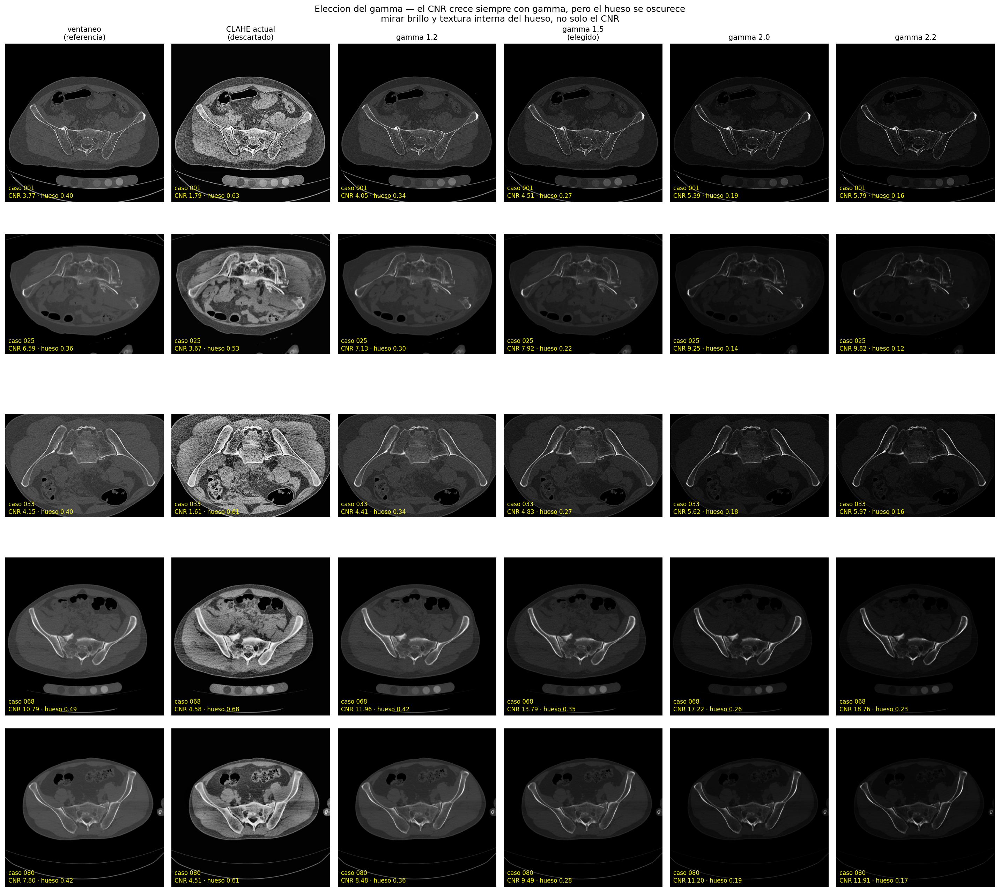

In [3]:
# Ventaneo solo vs. CLAHE descartado vs. escalera de gamma, en los 5 casos de referencia
salida_gamma = run('python src/comparar_gamma.py')
display(Image('outputs/eda/comparacion_gamma.png', width=1100))

### 1.1 Revisión visual de los 100 casos preprocesados

Para cada caso: el corte axial con más hueso etiquetado, tal como entra al modelo (gamma 1.5), con el contorno de la máscara en rojo y el **brillo medio del hueso** `b` en el título. Criterio de revisión: hueso claro y con textura interna, tejido blando uniforme y oscuro, sin granulado, contorno sobre el hueso. La figura se guarda en `outputs/figures/revision_preprocesamiento_100_casos.png` (tarda ~1–2 min: carga los 100 volúmenes).

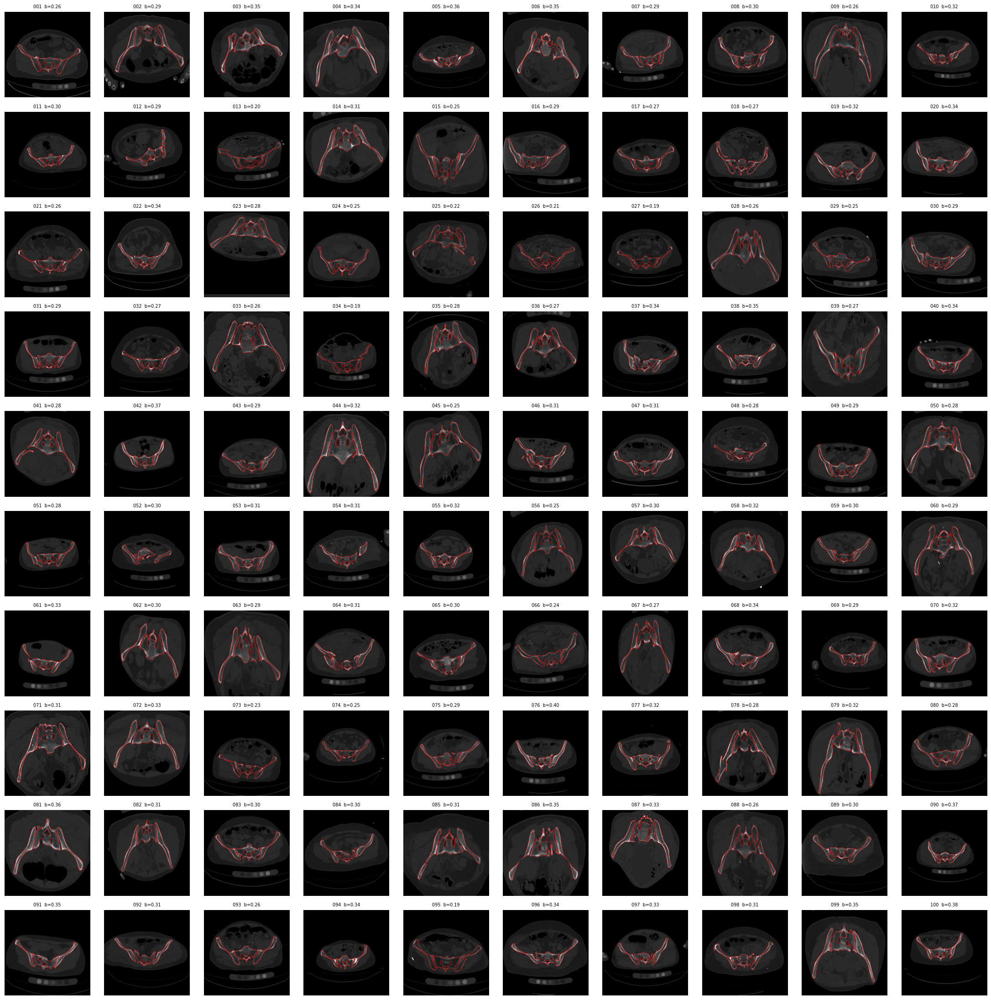

In [4]:
from pengwin_io import load_case, window_hu, resize_slice, resize_label_slice
from experimento_normalizacion import corte_con_mas_hueso
%matplotlib inline
# (experimento_normalizacion fija el backend 'Agg' al importarse; esta línea lo devuelve a inline)

casos = [f'{i:03d}' for i in range(1, 101)]
brillo = {}
fig, axes = plt.subplots(10, 10, figsize=(22, 22))
for ax, cid in zip(axes.ravel(), casos):
    c = load_case(cid); z = corte_con_mas_hueso(c)
    img = resize_slice(window_hu(c.image[z]), 256); lab = resize_label_slice(c.label[z], 256)
    brillo[cid] = float(img[lab > 0].mean())
    ax.imshow(img, cmap='gray', vmin=0, vmax=1); ax.contour(lab > 0, levels=[0.5], colors='r', linewidths=0.4)
    ax.set_title(f'{cid}  b={brillo[cid]:.2f}', fontsize=7); ax.axis('off')
plt.tight_layout()
fig.savefig('outputs/figures/revision_preprocesamiento_100_casos.png', dpi=110)
plt.show(); plt.close(fig)

Brillo medio del hueso (gamma 1.5): media 0.296, desv. 0.042, mín 0.188 (034), máx 0.398 (076)
Casos atípicos (|z| > 2): {'013': 0.203, '026': 0.212, '027': 0.193, '034': 0.188, '076': 0.398, '095': 0.189}


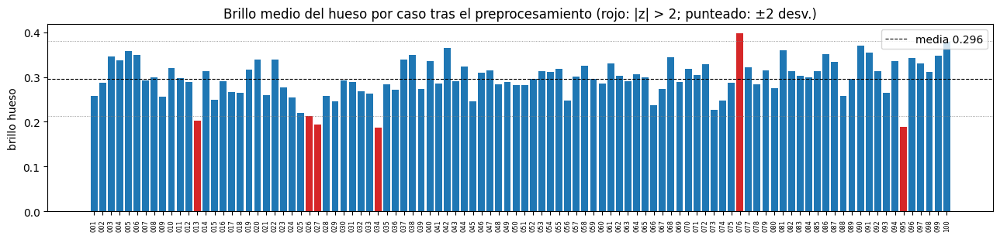

In [5]:
ids = np.array(list(brillo.keys())); vals = np.array(list(brillo.values()))
zs = (vals - vals.mean()) / vals.std()
atipicos = {i: round(float(v), 3) for i, v, z in zip(ids, vals, zs) if abs(z) > 2}
print(f'Brillo medio del hueso (gamma 1.5): media {vals.mean():.3f}, desv. {vals.std():.3f}, '
      f'mín {vals.min():.3f} ({ids[vals.argmin()]}), máx {vals.max():.3f} ({ids[vals.argmax()]})')
print('Casos atípicos (|z| > 2):', atipicos)

fig, ax = plt.subplots(figsize=(13, 3.2))
ax.bar(ids, vals, color=['tab:red' if i in atipicos else 'tab:blue' for i in ids])
ax.axhline(vals.mean(), color='k', lw=0.8, ls='--', label=f'media {vals.mean():.3f}')
for s in (-2, 2):
    ax.axhline(vals.mean() + s * vals.std(), color='gray', lw=0.6, ls=':')
ax.set_ylabel('brillo hueso'); ax.legend(loc='upper right')
ax.set_title('Brillo medio del hueso por caso tras el preprocesamiento (rojo: |z| > 2; punteado: ±2 desv.)')
plt.xticks(rotation=90, fontsize=6); plt.tight_layout(); plt.show(); plt.close(fig)

**Lectura (corrida del equipo con los 100 casos):**

- El brillo medio del hueso fue **0.296** en promedio, entre **0.188 (caso 034)** y **0.398 (caso 076)**. Ningún caso queda con el hueso apagado ni saturado.
- Atípicos con |z| > 2: **013, 026, 027, 034 y 095** (más oscuros) y **076** (más claro). El caso **025**, que era el más oscuro de los 5 casos del experimento de normalización (0.22), **no es atípico** entre los 100: está dentro de la variación normal.
- En la cuadrícula el contorno rojo cae sobre el hueso en todos los casos, el tejido blando se ve uniforme y no aparece el granulado que producía CLAHE. Los casos oscuros siguen mostrando la cortical con claridad; lo que cambia es el brillo del hueso esponjoso.
- **Decisión:** no se aplica normalización por caso. Gamma es global a propósito (cada vóxel depende solo de su HU, igual en entrenamiento e inferencia); corregir casos puntuales sería un preprocesamiento a medida que no se puede aplicar a un caso nuevo sin verlo antes. La diferencia de brillo entre escáneres queda documentada como **limitación**; si afecta la detección, se aborda con aumento de intensidad en el entrenamiento, no con un ajuste por caso.

### 1.2 Justificación con Otsu contra las máscaras del dataset (pedido del avance)

El profesor pidió decidir el preprocesamiento por **qué tan bien deja sacar el hueso**, no solo por contraste: a cada variante se le aplica un umbral de **Otsu** dentro del cuerpo y la máscara que sale se compara con la máscara de PENGWIN (Dice, precisión y recall) en 5 casos al azar × 5 cortes. Variantes: ventaneo, gamma 1.5 (la elegida), gamma 2.0, CLAHE, CLAHE + gamma 1.5 y ecualización global.

Se agregan dos columnas para no sacar conclusiones equivocadas:

- **Dice óptimo:** el mejor Dice que se puede lograr con *algún* umbral sobre esa imagen. Mide cuánta información del hueso conserva la imagen, sin depender de dónde cae Otsu.
- **Otsu sin fémur:** el label de PENGWIN solo marca la pelvis; el fémur y la columna son hueso pero cuentan como error para todas las variantes. Esta columna repite Otsu quitando del cuerpo el hueso que no está en el label.

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/otsu_preprocesamiento.py --n-casos 5 --cortes-por-caso 5 --seed 42
caso 004: 5 cortes evaluados
caso 015: 5 cortes evaluados
caso 036: 5 cortes evaluados
caso 082: 5 cortes evaluados
caso 095: 5 cortes evaluados

Casos: ['004', '015', '036', '082', '095'] | 5 cortes por caso | Otsu dentro del cuerpo vs label > 0
variante               Dice Otsu  precisión  recall  Dice mín  Dice óptimo  Otsu sin fémur
ventaneo                   0.480      0.514   0.684     0.130        0.670           0.526
gamma 1.5 (elegido)        0.486      0.671   0.446     0.148        0.670           0.552
gamma 2.0                  0.422      0.685   0.349     0.025        0.670           0.491
CLAHE                      0.223      0.133   0.905     0.091        0.595           0.227
CLAHE + gamma 1.5          0.288      0.201   0.880     0.096        0.616           0.266
ecualización global        0

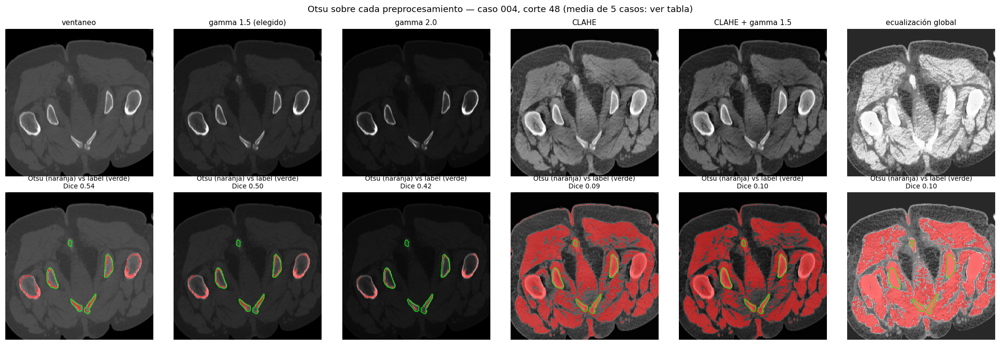

Dice Otsu    → ventaneo 0.480 | gamma 1.5 0.486 | CLAHE 0.223
Dice óptimo  → ventaneo 0.670 | gamma 1.5 0.670 | CLAHE 0.595
Diferencia ventaneo − gamma 1.5: con Otsu -0.006, con umbral óptimo +0.000


In [6]:
salida_otsu = run('python src/otsu_preprocesamiento.py --n-casos 5 --cortes-por-caso 5 --seed 42')
display(Image('outputs/eda/otsu_preprocesamiento.png', width=1300))
otsu = json.load(open('outputs/eda/otsu_preprocesamiento.json'))['resumen']
v, g, c = otsu['ventaneo'], otsu['gamma 1.5 (elegido)'], otsu['CLAHE']
print(f"Dice Otsu    → ventaneo {v['dice']:.3f} | gamma 1.5 {g['dice']:.3f} | CLAHE {c['dice']:.3f}")
print(f"Dice óptimo  → ventaneo {v['dice_optimo']:.3f} | gamma 1.5 {g['dice_optimo']:.3f} | CLAHE {c['dice_optimo']:.3f}")
print(f"Diferencia ventaneo − gamma 1.5: con Otsu {v['dice'] - g['dice']:+.3f}, con umbral óptimo "
      f"{v['dice_optimo'] - g['dice_optimo']:+.3f}")

**Lectura (corrida del equipo, casos 004, 015, 036, 082 y 095):**

- **Gamma 1.5 no pierde nada de hueso frente al ventaneo.** Los dos tienen exactamente el mismo Dice óptimo (0.670), igual que gamma 2.0 y la ecualización global. No es casualidad: son funciones crecientes de la misma imagen, así que cualquier máscara que salga de un umbral en una sale con otro umbral en la otra.
- **CLAHE sí pierde información.** Su Dice óptimo baja a 0.595 (0.616 con gamma): al cambiar los grises según la zona, ningún umbral logra separar el hueso tan bien como en la ventana. Con Otsu es el peor (Dice 0.22): realza el tejido blando y Otsu se lleva músculo y grasa (precisión 0.13). Esto confirma, con el criterio que pidió el profesor, haberlo descartado.
- **Con Otsu, gamma 1.5 queda primero** (Dice 0.486, contra 0.480 del ventaneo): pierde un poco de recall (0.45 contra 0.68) pero gana bastante precisión (0.67 contra 0.51), porque oscurece el tejido blando y Otsu ya no se lo lleva. La diferencia entre los dos es pequeña y viene de dónde cae el umbral, no de la información.
- **Por qué los Dice no son más altos:** el label solo marca la pelvis, y Otsu también marca el fémur, la columna y el hueso de los cortes con mucho tejido. Quitando ese hueso no etiquetado, gamma 1.5 sube a 0.552. Además el Dice mínimo (0.15) muestra que en algunos cortes un solo umbral no alcanza, que es justo lo que tiene que resolver el modelo.
- **Decisión:** se mantiene gamma 1.5. Conserva toda la información del hueso, separa mejor que el ventaneo con Otsu y tiene menos ruido en el tejido blando (CNR, sección 1).

## 2. Arquitectura

`src/week9_detection.py`, escrita desde cero (sin pesos preentrenados):

- **`FundidoraBackbone`**: 4 bloques convolucionales (conv 3×3 stride 2 + BN + ReLU, conv 3×3 + BN + ReLU); reduce la imagen ×16 (256 → 16) y el número de canales llega a 8 × `base_channels`.
- **`CBAM`**: atención de canal (qué filtros importan) y espacial (dónde mirar), al final del backbone, antes de la cabeza. Con `use_cbam=False` se reemplaza por `nn.Identity` → rama de control de la ablación (mismo modelo, sin atención).
- **`GridDetectionHead`**: grid 16×16; por celda predice objectness, caja `(cx, cy, w, h)` y clase (sacro / coxal izquierdo / coxal derecho) → 1 + 4 + 3 = 8 valores.
- **Pérdida**: BCE de objectness + Smooth L1 de la caja + entropía cruzada de la clase.
- **Post-proceso**: `decode_predictions` (umbral de confianza) + **NMS propio por clase** escrito en PyTorch.
- **Target**: `labels_to_grid` asigna cada región a la celda de su centro; si dos regiones caen en la misma celda, la segunda se reubica en la celda libre más cercana dentro de su caja (antes se perdía).

In [7]:
import torch
from week9_detection import DetectionModel

x = torch.rand(1, 1, 256, 256)
parametros = {}
for cbam in (True, False):
    model = DetectionModel(base_channels=32, use_cbam=cbam).eval()
    with torch.no_grad():
        f = model.backbone(x); out = model(x)
    parametros[cbam] = sum(p.numel() for p in model.parameters())
    print(f'CBAM={str(cbam):5s}: mapa de características {tuple(f.shape)} → salida {tuple(out.shape)} '
          f'| parámetros {parametros[cbam]:,}')
print(f'CBAM agrega {parametros[True] - parametros[False]:,} parámetros '
      f'({100 * (parametros[True] - parametros[False]) / parametros[True]:.2f} % del modelo)')

CBAM=True : mapa de características (1, 256, 16, 16) → salida (1, 16, 16, 8) | parámetros 1,773,322
CBAM=False: mapa de características (1, 256, 16, 16) → salida (1, 16, 16, 8) | parámetros 1,765,032
CBAM agrega 8,290 parámetros (0.47 % del modelo)


## 3. Overfit intencional (prueba de correctitud)

Caso 001, 2 cortes, 150 épocas, modelo pequeño (8 canales base, con CBAM). Criterio del enunciado: la pérdida debe bajar **al menos 4×**. No mide desempeño: prueba que la cadena máscara → target de grid → backbone/CBAM → cabeza → pérdida → NMS está bien conectada. Si algo estuviera mal conectado (por ejemplo, el target no correspondiera a la imagen), el modelo no podría memorizar ni siquiera 2 cortes.

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/train_overfit_detection.py --output outputs/week9_overfit_detection.pth
epoch 0001 loss=1.67265 obj=0.17755 box=0.09368 cls=1.02670
epoch 0015 loss=0.10941 obj=0.10388 box=0.00108 cls=0.00011
epoch 0030 loss=0.04746 obj=0.04414 box=0.00052 cls=0.00070
epoch 0045 loss=0.01782 obj=0.01754 box=0.00003 cls=0.00015
epoch 0060 loss=0.00815 obj=0.00806 box=0.00001 cls=0.00006
epoch 0075 loss=0.00461 obj=0.00456 box=0.00000 cls=0.00004
epoch 0090 loss=0.00307 obj=0.00303 box=0.00000 cls=0.00003
epoch 0105 loss=0.00225 obj=0.00222 box=0.00000 cls=0.00002
epoch 0120 loss=0.00174 obj=0.00171 box=0.00000 cls=0.00002
epoch 0135 loss=0.00140 obj=0.00137 box=0.00000 cls=0.00002
epoch 0150 loss=0.00115 obj=0.00113 box=0.00000 cls=0.00002

Dispositivo: cpu
CBAM: si
Codificacion: 0 reubicadas, 0 descartadas
Pérdida inicial: 1.67265 | final: 0.00115
Reducción: 1452.1x
Predicciones del primer co

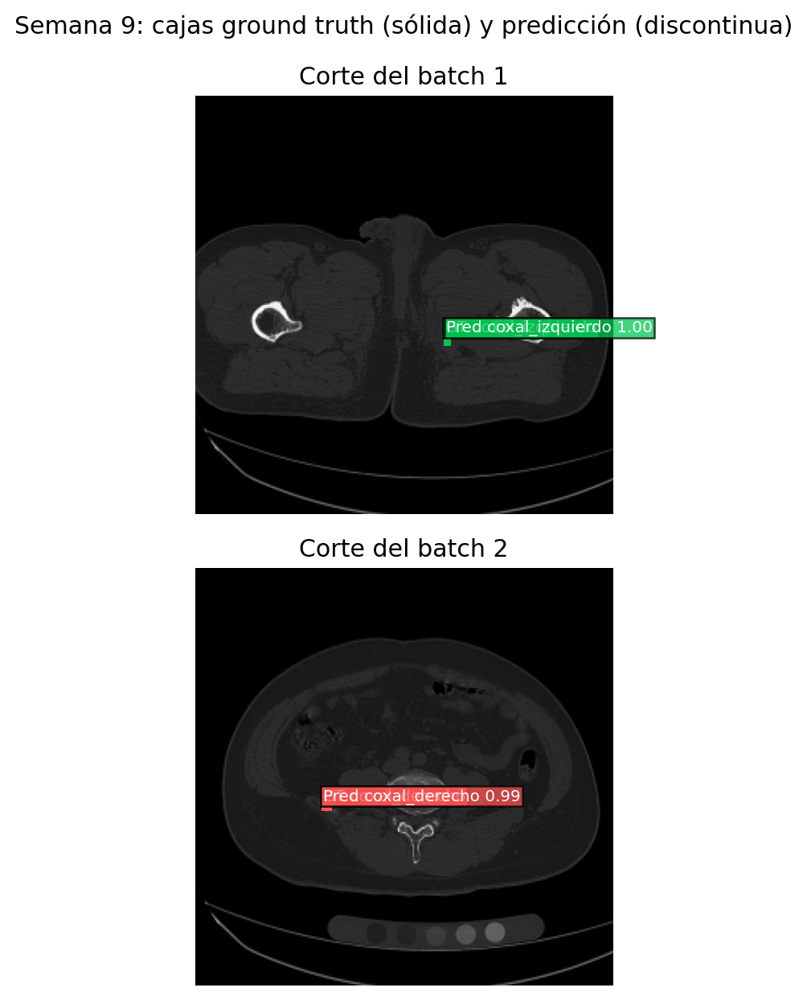


Pérdida 1.67265 → 0.00115: 1454.5× (cumple el criterio ≥ 4×)


In [8]:
salida_overfit = run('python src/train_overfit_detection.py --output outputs/week9_overfit_detection.pth')
_ = run('python src/visualize_overfit_detection.py --checkpoint outputs/week9_overfit_detection.pth '
        '--output outputs/figures/week9_detection_overfit.png')
display(Image('outputs/figures/week9_detection_overfit.png', width=900))

m = re.search(r'inicial:\s*([\d.]+)\s*\|\s*final:\s*([\d.]+)', salida_overfit)
overfit = {'inicial': float(m.group(1)), 'final': float(m.group(2))}
overfit['reduccion'] = overfit['inicial'] / max(overfit['final'], 1e-8)
print(f"\nPérdida {overfit['inicial']:.5f} → {overfit['final']:.5f}: {overfit['reduccion']:.1f}× "
      f"({'cumple' if overfit['reduccion'] >= 4 else 'NO cumple'} el criterio ≥ 4×)")

## 4. Caché y primer entrenamiento multi-paciente

**Caché:** 4 cortes por caso repartidos en la extensión ósea (15 %–85 %), de 24 casos de train y 15 de validación → 96 + 60 cortes de 256×256, con el preprocesamiento actual (gamma 1.5). Evita releer los volúmenes 3D en cada época.

**Entrenamiento:** dos corridas de 35 épocas con la misma semilla (42), los mismos datos y 32 canales base: **con CBAM** (el modelo) y **sin CBAM** (ablación). El checkpoint se elige por **F1 de detección a IoU ≥ 0.5**, no por IoU medio: el IoU medio solo mira la mejor predicción de cada caja real e ignora las que sobran (en una corrida eligió una época con 2112 cajas predichas para 164 reales, precisión 3 %).

Además, por el pedido del avance, se entrena un tercer modelo: **CBAM en tres etapas con γ aprendible** (sección 4.1).

Los `.pth` **no están en el repositorio** (pesan y se regeneran), solo los historiales `.json`. Por eso:

- Si el `.pth` **no existe**, la celda entrena (en CPU, del orden de 10–20 min por modelo).
- Si ya existe **y corresponde a su historial `.json`**, se reutiliza y solo se muestra su resumen. Si no corresponde (por ejemplo, un `.pth` viejo en tu carpeta y un `.json` nuevo que llegó con `git pull`), se reentrena para que curvas, tabla y cajas salgan del mismo modelo.
- Para forzar el reentrenamiento: `REENTRENAR = True`.

In [9]:
REENTRENAR = False     # True: regenera caché y vuelve a entrenar aunque existan los archivos
EPOCAS = 35            # configuración documentada de la semana 9
CACHE = 'data/cache/week9_detection_slices.npz'
MODELOS = {'con CBAM': ('outputs/week9_det_cbam32.pth', ''),
           'sin CBAM': ('outputs/week9_det_nocbam32.pth', '--no-cbam'),
           # Avance semana 9: CBAM en tres etapas con γ aprendible (sección 4.1)
           'CBAM 3 etapas + γ': ('outputs/week9_det_cbam3g.pth', '--cbam-stages 3 --learnable-gamma')}

if REENTRENAR or not Path(CACHE).exists():
    _ = run(f'python src/prepare_week9_detection_data.py --output {CACHE}')
else:
    print(f'Caché existente: {CACHE}')
d = np.load(CACHE)
print('cortes por split:', {s: int((d['split_names'] == s).sum()) for s in ('train', 'val', 'test')},
      '| tamaño', d['images'].shape[1:])

Caché existente: data/cache/week9_detection_slices.npz
cortes por split: {'train': 96, 'val': 60, 'test': 0} | tamaño (1, 256, 256)


In [10]:
def misma_corrida(ckpt):
    # El .pth no se versiona y el .json sí: tras un git pull pueden venir de corridas distintas.
    j = Path(ckpt).with_suffix('.json')
    if not (Path(ckpt).exists() and j.exists()):
        return False
    ck = torch.load(ckpt, map_location='cpu', weights_only=False)
    h = json.load(open(j))
    f1_json = h['historial'][h['mejor_epoca'] - 1]['f1']
    ok = ck.get('best_epoch') == h['mejor_epoca'] and abs(ck.get('best_val_f1', -1) - f1_json) < 1e-6
    if not ok:
        print(f"Aviso: {ckpt} (época {ck.get('best_epoch')}, F1 {ck.get('best_val_f1', float('nan')):.3f}) y su .json "
              f"(época {h['mejor_epoca']}, F1 {f1_json:.3f}) no son de la misma corrida → se reentrena.")
    return ok


def entrenar(nombre):
    ckpt, flag = MODELOS[nombre]
    if REENTRENAR or not misma_corrida(ckpt):
        _ = run(f'python src/train_week9_detection.py {flag} --epochs {EPOCAS} --output {ckpt}')
    else:
        h = json.load(open(Path(ckpt).with_suffix('.json')))
        b = h['historial'][h['mejor_epoca'] - 1]
        print(f"{nombre}: se reutiliza {ckpt} — mejor época {h['mejor_epoca']}, F1={b['f1']:.3f}, "
              f"P={b['precision']:.3f}, R={b['recall']:.3f}, FP={int(b['falsos_positivos'])}")

entrenar('con CBAM')

con CBAM: se reutiliza outputs/week9_det_cbam32.pth — mejor época 34, F1=0.560, P=0.480, R=0.671, FP=119


In [11]:
entrenar('sin CBAM')

sin CBAM: se reutiliza outputs/week9_det_nocbam32.pth — mejor época 32, F1=0.508, P=0.409, R=0.671, FP=159


### 4.1 Aporte de la atención por capa: CBAM en tres etapas con γ aprendible (pedido del avance)

El profesor pidió medir **cuánto aporta la atención en cada capa** con un valor que el modelo aprende durante el entrenamiento. Se agrega un escalar **γ por etapa** y CBAM se aplica tras los bloques 2, 3 y 4 del backbone (mapas /4, /8 y /16):

$$\text{salida} = x + \gamma\,(\text{CBAM}(x) - x), \qquad \gamma_{\text{inicial}} = 0$$

Con γ = 0 la capa deja pasar la entrada sin atención; con γ = 1 aplica CBAM completo. γ se aprende con el resto de la red, así que su valor final dice cuánto decidió usar la atención el propio modelo. Lectura propuesta por el profesor: |γ| ≈ 0 → no aporta; |γ| > 0.5 → aporta; γ negativo → el modelo invierte el mapa de atención (se mira el valor absoluto). Es el mismo entrenamiento que los otros dos modelos (35 épocas, semilla 42); una prueba unitaria verifica que con γ = 0 el modelo calcula exactamente lo mismo que el de control sin CBAM.

In [12]:
entrenar('CBAM 3 etapas + γ')

CBAM 3 etapas + γ: se reutiliza outputs/week9_det_cbam3g.pth — mejor época 35, F1=0.542, P=0.447, R=0.689, FP=140


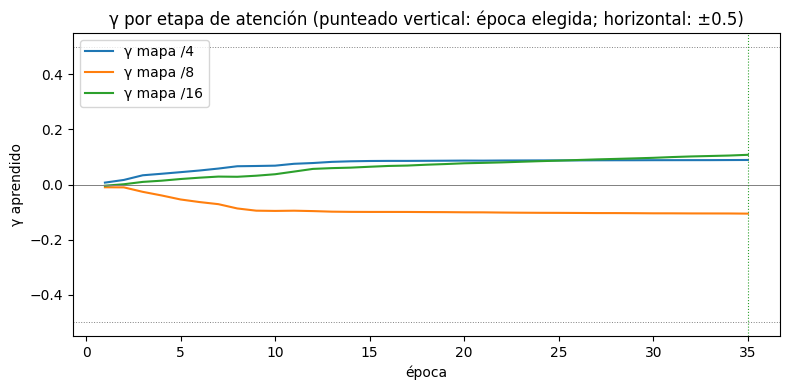

   etapa   γ (época elegida)  lectura (criterio del profesor)
      /4               0.089  no aporta
      /8              -0.106  aporte parcial  (signo negativo: invierte la atención)
     /16               0.108  aporte parcial
γ máximo en valor absoluto: 0.108


In [13]:
h3 = json.load(open(Path(MODELOS['CBAM 3 etapas + γ'][0]).with_suffix('.json')))
hist3 = h3['historial']; ep3 = [r['epoch'] for r in hist3]
gkeys = sorted([k for k in hist3[0] if k.startswith('gamma_')], key=lambda k: int(k.split('_')[-1]))
fig, ax = plt.subplots(figsize=(8, 4))
for k in gkeys:
    ax.plot(ep3, [r[k] for r in hist3], label='γ mapa /' + k.split('_')[-1])
for y, st in ((0, '-'), (0.5, ':'), (-0.5, ':')):
    ax.axhline(y, color='gray', lw=0.7, ls=st)
ax.axvline(h3['mejor_epoca'], color='tab:green', lw=0.8, ls=':')
ax.set_xlabel('época'); ax.set_ylabel('γ aprendido')
ax.set_title('γ por etapa de atención (punteado vertical: época elegida; horizontal: ±0.5)')
ax.legend(); plt.tight_layout(); fig.savefig('outputs/figures/week9_gammas_atencion.png', dpi=120)
plt.show(); plt.close(fig)

b3 = hist3[h3['mejor_epoca'] - 1]
gammas = {k.split('_')[-1]: b3[k] for k in gkeys}
print(f"{'etapa':>8s}{'γ (época elegida)':>20s}  lectura (criterio del profesor)")
for et, gv in gammas.items():
    lect = 'aporta' if abs(gv) > 0.5 else ('aporte parcial' if abs(gv) > 0.1 else 'no aporta')
    print(f"{'/' + et:>8s}{gv:>20.3f}  {lect}" + ('  (signo negativo: invierte la atención)' if gv < -0.1 else ''))
print(f"γ máximo en valor absoluto: {max(abs(x) for x in gammas.values()):.3f}")

**Lectura (corrida del equipo):**

- **γ final por etapa:** /4 = +0.089, /8 = −0.106 y /16 = +0.108. Con el criterio del profesor ninguna etapa llega a 0.5: la atención **aporta poco** en este modelo. La de /4 casi no aporta, y la de /8 tiene signo negativo, es decir que el modelo usa ese mapa de atención invertido.
- **La etapa /16 sigue creciendo al final** (de +0.057 en la época 12 a +0.108 en la 35), mientras /4 y /8 se estabilizaron hacia la época 15. Es la etapa más cercana a la cabeza, donde cada celda decide si hay una región, y es la única que el modelo sigue reforzando. Con más épocas o más datos podría seguir subiendo, así que un γ pequeño aquí no es una prueba de que la atención sea inútil.
- **En F1, el modelo de tres etapas** (0.542 al umbral 0.20) queda entre el de una etapa (0.560) y el de control sin CBAM (0.508); la diferencia con el de control (+0.034) es menor que el ruido entre épocas, así que no es concluyente. Con el post-proceso de una caja por clase llega a **0.627** (umbral 0.30), el mejor de los tres modelos, pero tampoco es una diferencia concluyente con una sola semilla.
- Se lee junto con el Grad-CAM (5.2), donde sí aparece una diferencia en dónde mira el modelo.

## 5. Curvas, ablación de CBAM y umbral de confianza

Mismo color por modelo; en el panel derecho la precisión va en línea discontinua y el recall en continua.

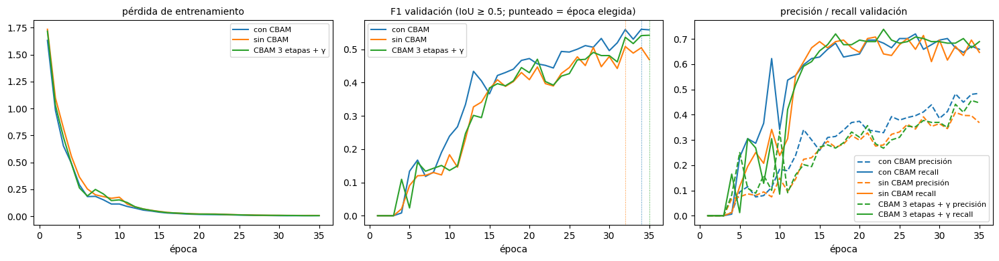

modelo              época      F1       P       R     IoU    FP   pred  reales
con CBAM               34   0.560   0.480   0.671   0.524   119    229     164
sin CBAM               32   0.508   0.409   0.671   0.512   159    269     164
CBAM 3 etapas + γ      35   0.542   0.447   0.689   0.520   140    253     164

Salto medio del F1 entre épocas consecutivas (últimas 10): con CBAM 0.023, sin CBAM 0.038, CBAM 3 etapas + γ 0.019
Ablación con umbral 0.20: diferencia +0.052, menor que 2× el salto típico entre épocas (0.076) → no concluyente
CBAM 3 etapas + γ vs sin CBAM: diferencia +0.034, menor que 2× el salto típico entre épocas (0.076) → no concluyente


In [14]:
COLOR = {'con CBAM': 'tab:blue', 'sin CBAM': 'tab:orange', 'CBAM 3 etapas + γ': 'tab:green'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
mejores = {}
for name, (ckpt, _flag) in MODELOS.items():
    h = json.load(open(Path(ckpt).with_suffix('.json'))); hist = h['historial']
    ep = [r['epoch'] for r in hist]; col = COLOR[name]
    axes[0].plot(ep, [r['train_loss'] for r in hist], color=col, label=name)
    axes[1].plot(ep, [r['f1'] for r in hist], color=col, label=name)
    axes[1].axvline(h['mejor_epoca'], color=col, lw=0.7, ls=':')
    axes[2].plot(ep, [r['precision'] for r in hist], '--', color=col, label=f'{name} precisión')
    axes[2].plot(ep, [r['recall'] for r in hist], '-', color=col, label=f'{name} recall')
    mejores[name] = hist[h['mejor_epoca'] - 1]
titulos = ['pérdida de entrenamiento', 'F1 validación (IoU ≥ 0.5; punteado = época elegida)',
           'precisión / recall validación']
for ax, t in zip(axes, titulos):
    ax.set_title(t, fontsize=10); ax.set_xlabel('época'); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig('outputs/figures/week9_curvas_cbam_vs_nocbam.png', dpi=120)
plt.show(); plt.close(fig)

print(f"{'modelo':18s} {'época':>6s} {'F1':>7s} {'P':>7s} {'R':>7s} {'IoU':>7s} {'FP':>5s} {'pred':>6s} {'reales':>7s}")
for name, b in mejores.items():
    print(f"{name:18s} {b['epoch']:6d} {b['f1']:7.3f} {b['precision']:7.3f} {b['recall']:7.3f} "
          f"{b['iou_medio']:7.3f} {int(b['falsos_positivos']):5d} {int(b['n_pred']):6d} {int(b['n_gt']):7d}")

# Ruido de la validación: cuánto salta el F1 de una época a la siguiente en las últimas 10 épocas.
ruido = {}
for name, (ckpt, _flag) in MODELOS.items():
    f1s = np.array([r['f1'] for r in json.load(open(Path(ckpt).with_suffix('.json')))['historial']][-10:])
    ruido[name] = float(np.abs(np.diff(f1s)).mean())
RUIDO_F1 = max(ruido.values())


def veredicto(f1_con, f1_sin):
    dif = f1_con - f1_sin
    if abs(dif) <= 2 * RUIDO_F1:
        return f'diferencia {dif:+.3f}, menor que 2× el salto típico entre épocas ({2 * RUIDO_F1:.3f}) → no concluyente'
    lado = 'a favor de CBAM' if dif > 0 else 'en contra de CBAM'
    return f'diferencia {dif:+.3f}, mayor que 2× el salto típico entre épocas ({2 * RUIDO_F1:.3f}) → {lado} (una sola semilla)'


print(f"\nSalto medio del F1 entre épocas consecutivas (últimas 10): "
      + ', '.join(f'{k} {v:.3f}' for k, v in ruido.items()))
print('Ablación con umbral 0.20:', veredicto(mejores['con CBAM']['f1'], mejores['sin CBAM']['f1']))
print('CBAM 3 etapas + γ vs sin CBAM:', veredicto(mejores['CBAM 3 etapas + γ']['f1'], mejores['sin CBAM']['f1']))

**Lectura de las curvas y de la ablación:**

- La pérdida de entrenamiento cae casi a cero hacia la época 20 en los dos modelos, mientras el F1 de validación sigue subiendo a saltos hasta ~0.5: el modelo **memoriza los 96 cortes de entrenamiento** y la validación es ruidosa porque son solo 60 cortes (164 cajas reales). Más datos y aumento de datos son el siguiente paso natural.
- Con el umbral de entrenamiento (0.20) el recall (~0.65–0.70) es bastante mayor que la precisión (~0.40): el modelo encuentra la mayoría de las regiones pero **propone cajas de más** (del orden de una caja sobrante por cada caja real).
- **Cómo se decide la ablación:** el F1 de validación salta de una época a otra (la celda anterior imprime cuánto). Una diferencia entre con y sin CBAM menor que el doble de ese salto se trata como **no concluyente**; la celda imprime el veredicto en vez de escribirlo a mano. Con una sola semilla y 15 casos de validación, incluso una diferencia mayor es un indicio, no una prueba. En una corrida previa con 8 canales la diferencia fue clara (F1 0.31 con CBAM contra 0.21 sin CBAM), lo que sugiere que la atención ayuda más cuando el modelo tiene poca capacidad.
- **Decisión:** CBAM se mantiene porque es requisito del enunciado y cuesta solo el 0.47 % de los parámetros. Para una conclusión firme haría falta repetir con varias semillas.

### 5.1 Post-proceso: umbral de confianza y una caja por región

Durante el entrenamiento se evalúa con confianza ≥ 0.20 y con **todas** las cajas que sobreviven al NMS. Eso deja dos fuentes de cajas sobrantes:

- **El NMS solo elimina cajas que se solapan.** Compara cada caja con las de mayor puntaje de su clase y borra las que tengan IoU > 0.5. No mira la diferencia de puntaje: una caja de 0.45 que cubre la mitad inferior del coxal y otra de 0.95 que cubre la superior se solapan poco y **sobreviven las dos**.
- **Pero en cada corte hay a lo sumo una caja real por región** (`boxes_from_label` arma una sola caja por sacro, coxal izquierdo y coxal derecho). Entonces cualquier segunda caja de la misma clase es, por construcción, un falso positivo. `decode_predictions(..., max_por_clase=1)` se queda solo con la de mayor puntaje de cada clase. No es un ajuste a un caso: es una restricción del problema, la misma que ya aplicaba el visualizador del entregable.

Se barre el umbral con los dos modos (todas las cajas / una por clase) sobre validación, sin reentrenar: es solo post-proceso.

In [15]:
from train_week9_detection import evaluar_deteccion
from week9_detection import detection_model_from_checkpoint

val = np.asarray(d['split_names'] == 'val')
val_x = torch.from_numpy(d['images'][val].astype(np.float32))
val_y = torch.from_numpy(d['labels'][val].astype(np.int64))

UMBRALES = (0.1, 0.2, 0.3, 0.4, 0.5, 0.6)
MODOS = {'todas': None, '1 por clase': 1}
barrido = {}
for name, (ckpt, _flag) in MODELOS.items():
    model = detection_model_from_checkpoint(torch.load(ckpt, map_location='cpu', weights_only=False))
    model.eval()
    for modo, mpc in MODOS.items():
        for conf in UMBRALES:
            barrido[(name, modo, conf)] = evaluar_deteccion(model, val_x, val_y, torch.device('cpu'),
                                                            confidence=conf, max_por_clase=mpc)

print(f"{'modelo':18s} {'cajas':>12s} {'conf':>5s} {'F1':>7s} {'P':>7s} {'R':>7s} {'FP':>5s} {'pred':>6s}")
for (name, modo, conf), m in barrido.items():
    print(f"{name:18s} {modo:>12s} {conf:5.2f} {m['f1']:7.3f} {m['precision']:7.3f} {m['recall']:7.3f} "
          f"{int(m['falsos_positivos']):5d} {int(m['n_pred']):6d}")

MODO, UMBRAL = max(((mo, c) for mo in MODOS for c in UMBRALES),
                   key=lambda k: barrido[('con CBAM', k[0], k[1])]['f1'])
MAX_POR_CLASE = MODOS[MODO]
mejor_todas = max(UMBRALES, key=lambda c: barrido[('con CBAM', 'todas', c)]['f1'])
print(f"\nMejor post-proceso para el modelo con CBAM: cajas = {MODO}, confianza ≥ {UMBRAL:.2f} "
      f"(F1 {barrido[('con CBAM', MODO, UMBRAL)]['f1']:.3f}; con todas las cajas el mejor era "
      f"{barrido[('con CBAM', 'todas', mejor_todas)]['f1']:.3f} a {mejor_todas:.2f})")
print(f'Ablación con ese post-proceso:',
      veredicto(barrido[('con CBAM', MODO, UMBRAL)]['f1'], barrido[('sin CBAM', MODO, UMBRAL)]['f1']))
print(f'CBAM 3 etapas + γ vs sin CBAM con ese post-proceso:',
      veredicto(barrido[('CBAM 3 etapas + γ', MODO, UMBRAL)]['f1'], barrido[('sin CBAM', MODO, UMBRAL)]['f1']))

modelo                    cajas  conf      F1       P       R    FP   pred
con CBAM                  todas  0.10   0.468   0.349   0.707   216    332
con CBAM                  todas  0.20   0.560   0.480   0.671   119    229
con CBAM                  todas  0.30   0.575   0.543   0.610    84    184
con CBAM                  todas  0.40   0.586   0.594   0.579    65    160
con CBAM                  todas  0.50   0.564   0.627   0.512    50    134
con CBAM                  todas  0.60   0.515   0.663   0.421    35    104
con CBAM            1 por clase  0.10   0.612   0.608   0.616    65    166
con CBAM            1 por clase  0.20   0.616   0.642   0.591    54    151
con CBAM            1 por clase  0.30   0.598   0.657   0.549    47    137
con CBAM            1 por clase  0.40   0.582   0.664   0.518    43    128
con CBAM            1 por clase  0.50   0.551   0.679   0.463    36    112
con CBAM            1 por clase  0.60   0.504   0.691   0.396    29     94
sin CBAM                 

**Lectura:**

- **Con todas las cajas**, subir el umbral es la única forma de quitar sobrantes, y se paga en recall: el umbral alto también borra regiones reales que el modelo vio con poca confianza.
- **Con una caja por clase**, las sobrantes de la misma clase desaparecen sin tocar el umbral, así que el umbral puede quedarse más bajo. La precisión sube mucho, pero tiene un costo: a veces la caja de mayor puntaje **no** es la bien ubicada y la correcta, con menos puntaje, se descarta. Pasa porque el puntaje (objectness × probabilidad de clase) dice qué tan seguro está el modelo de que hay una región, no qué tan bien puso la caja. La sección 6.1 cuenta cuántos aciertos se pierden así; en balance, el F1 mejora.
- La celda imprime el post-proceso elegido (modo + umbral) y es el que usan el mosaico y la sección 6.1.

**Cuidado:** el modo y el umbral se eligieron mirando la **misma validación** con la que se miden, así que ese F1 es una cifra **optimista**. Quedan fijos desde aquí y la cifra que se reporte como resultado final se mide en el conjunto de **test**, que este caché no incluye a propósito (`test=0`).

### 5.2 Grad-CAM con y sin atención (pedido del avance)

El profesor pidió ver **dónde concentra la "energía" el modelo** para decidir, comparando con y sin atención. Para cada región (sacro, coxal izquierdo, coxal derecho) se toma la celda del grid con mayor puntaje de esa clase y se calcula qué píxeles de la imagen empujaron esa decisión.

- **Método:** se usa **HiResCAM**, la variante de Grad-CAM que multiplica gradiente por activación punto a punto en vez de promediar el gradiente por canal. El Grad-CAM clásico, al promediar, mezcla los gradientes de la celda que decide con canales que se activan en todo el corte: resalta el borde de **todos** los huesos del corte, no el de la región que se está detectando (abajo se muestra un caso con los dos métodos). Tomado sobre el mapa /16 y con el objectness de todo el corte, como en la primera versión de esta sección, el calor terminaba incluso en el fondo.
- **Smooth:** cada mapa es el promedio sobre 8 copias de la imagen con un poco de ruido (Smooth Grad-CAM), que lo hace más estable.
- **Capa:** el mapa /8 (32×32) del backbone, más fino que el /16 que entra a la cabeza.
- **Medida en números ("concentración de energía"):** qué fracción del mapa cae **dentro de la caja real** de la región, promediada sobre los 60 cortes de validación, para los tres modelos.

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/gradcam_week9.py --cache data/cache/week9_detection_slices.npz --modelos "con CBAM=outputs/week9_det_cbam32.pth" "sin CBAM=outputs/week9_det_nocbam32.pth" "CBAM 3 etapas + γ=outputs/week9_det_cbam3g.pth" --casos 024 014 067 095 087 --smooth 8
Smooth HiResCAM (N=8), mapa /8: fraccion de la energia dentro de la caja real (60 cortes de validacion)
modelo           CBAM 3 etapas + γ  con CBAM  sin CBAM
region                                                
coxal_derecho                0.638     0.319     0.471
coxal_izquierdo              0.621     0.569     0.522
sacro                        0.350     0.260     0.343
todas                        0.554     0.395     0.455
concentracion media (1 = mapa uniforme): {'CBAM 3 etapas + γ': 10.77, 'con CBAM': 8.04, 'sin CBAM': 9.28}
Guardado: outputs\figures\week9_gradcam_024.png
Guardado: outputs\figures\week9_gradcam_014.png
Guardado:

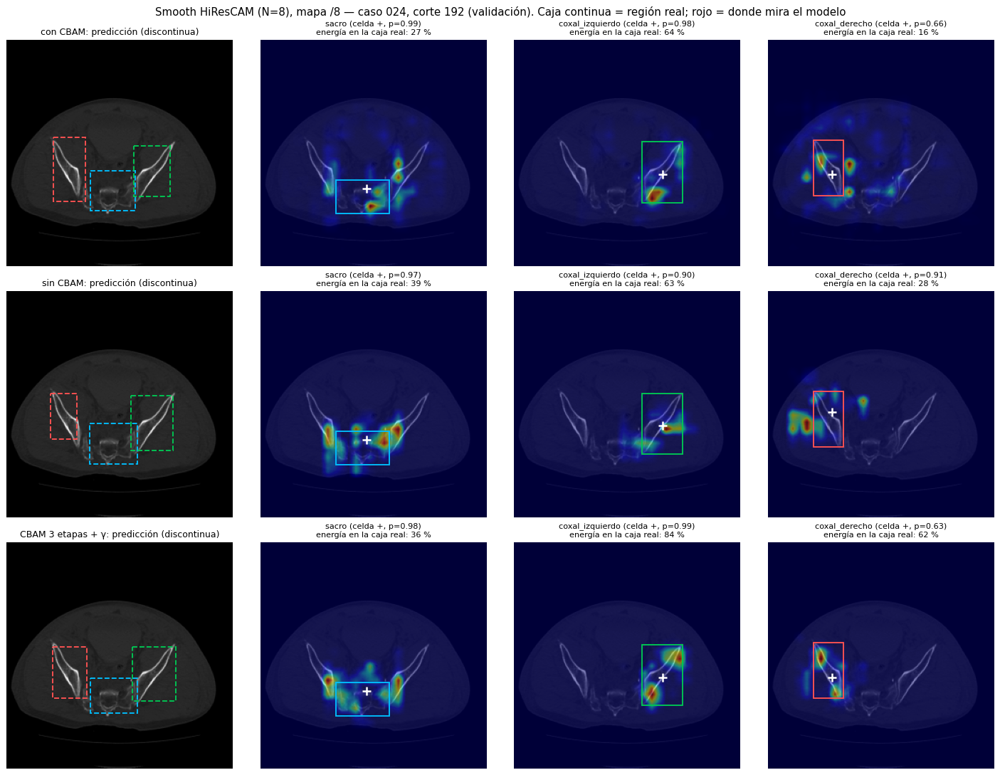

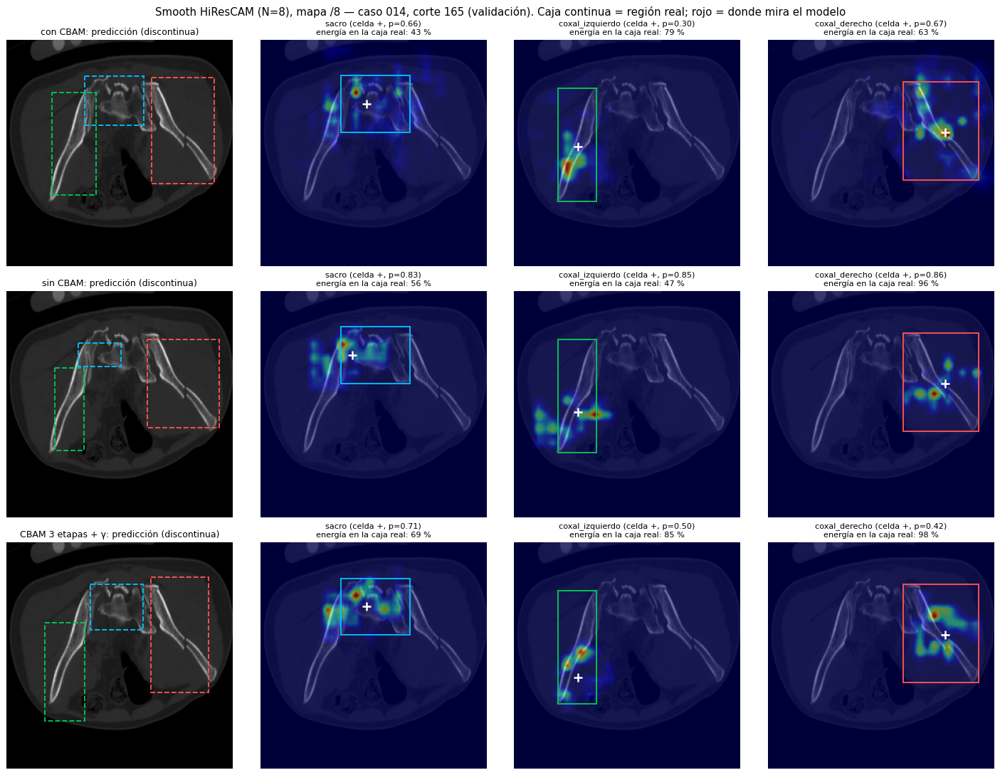

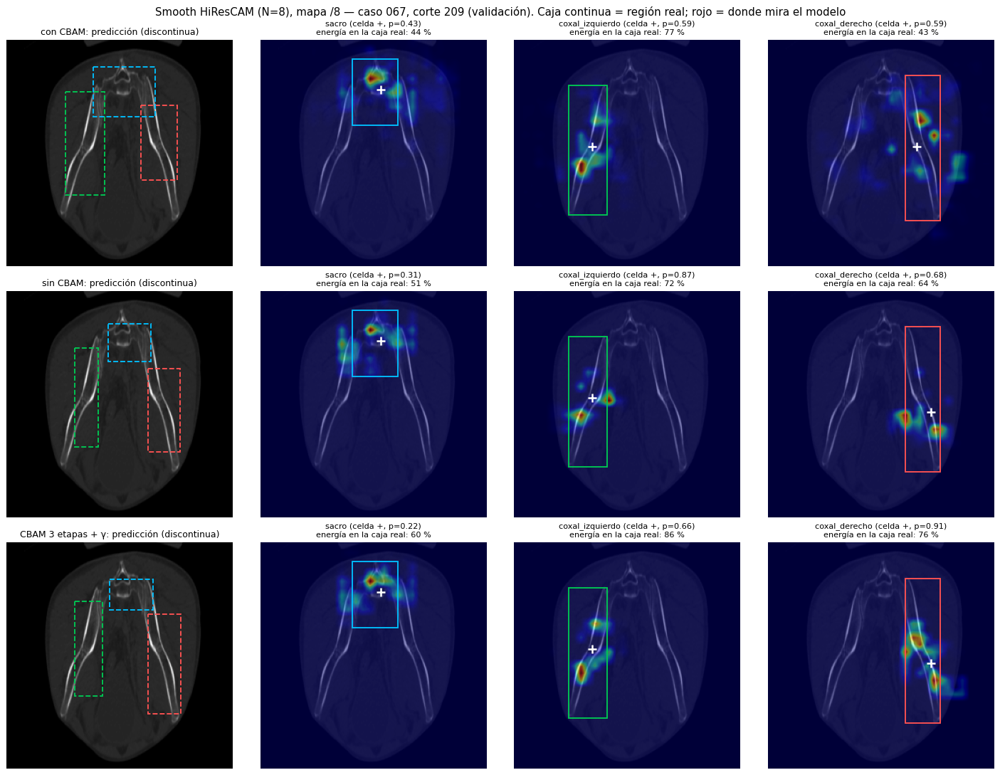

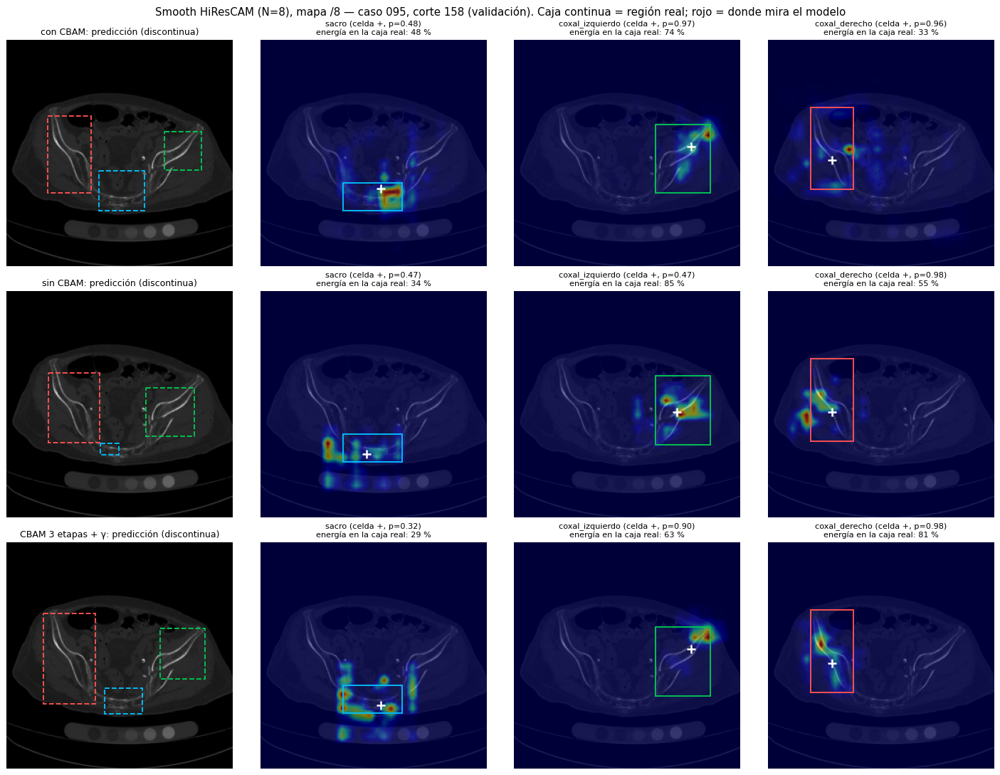

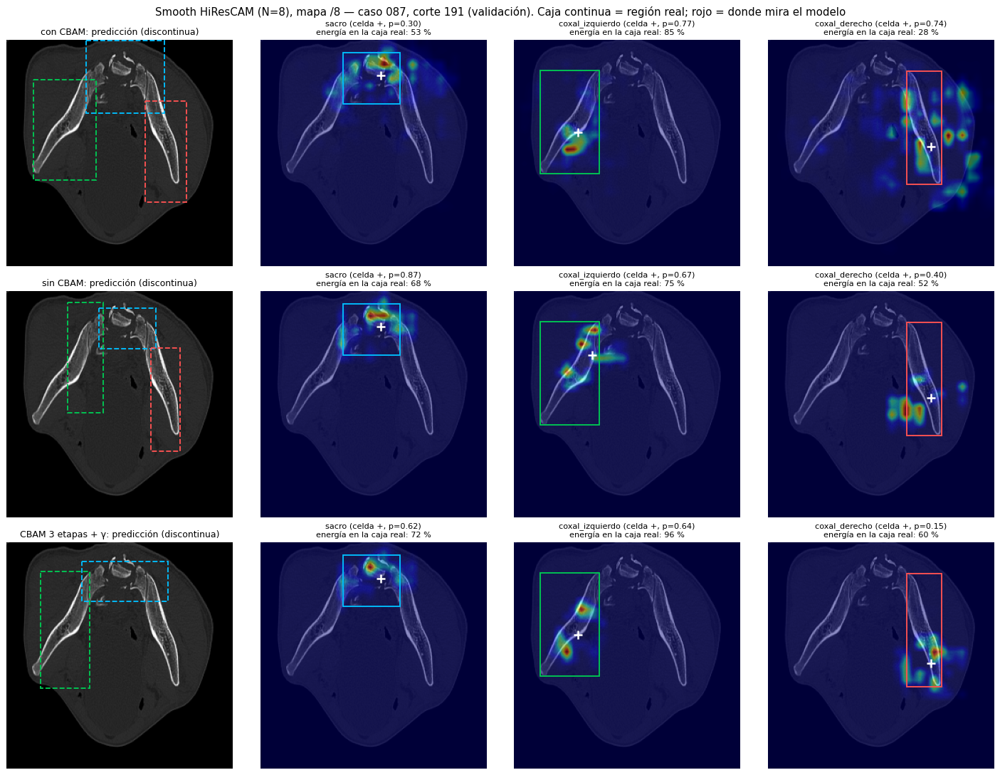


Fracción de la energía del mapa dentro de la caja real (60 cortes de validación):


modelo,CBAM 3 etapas + γ,con CBAM,sin CBAM
region,,,
coxal_derecho,63.8 %,31.9 %,47.1 %
coxal_izquierdo,62.1 %,56.9 %,52.2 %
sacro,35.0 %,26.0 %,34.3 %
todas,55.4 %,39.5 %,45.5 %


In [16]:
modelos_cam = ' '.join(f'"{n}={p}"' for n, (p, _f) in MODELOS.items())
salida_cam = run(f'python src/gradcam_week9.py --cache {CACHE} --modelos {modelos_cam} '
                 f'--casos 024 014 067 095 087 --smooth 8')
for cid in ['024', '014', '067', '095', '087']:
    ruta = Path(f'outputs/figures/week9_gradcam_{cid}.png')
    if ruta.exists():
        display(Image(str(ruta), width=1100))

energia = pd.read_csv('outputs/figures/week9_gradcam_energia.csv') if Path('outputs/figures/week9_gradcam_energia.csv').exists() else None
if energia is not None:
    tabla_cam = energia.pivot_table(index='region', columns='modelo', values='energia_en_caja', aggfunc='mean')
    tabla_cam.loc['todas'] = energia.groupby('modelo')['energia_en_caja'].mean()
    print('\nFracción de la energía del mapa dentro de la caja real (60 cortes de validación):')
    display((100 * tabla_cam).round(1).astype(str) + ' %')

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/gradcam_week9.py --cache data/cache/week9_detection_slices.npz --modelos "con CBAM=outputs/week9_det_cbam32.pth" --casos 014 --metodo gradcam --solo-figuras
Guardado: outputs\figures\week9_gradcam_014_gradcam.png


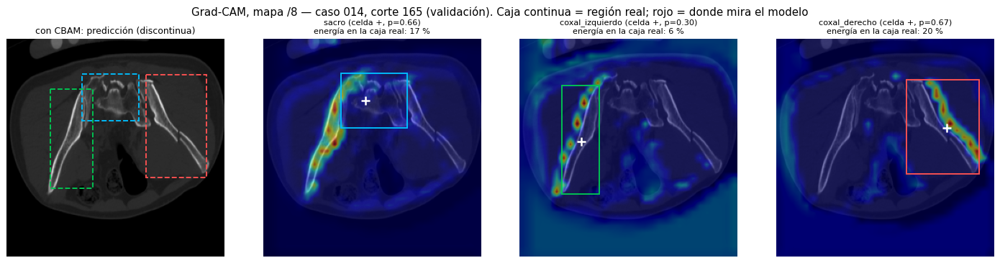

In [17]:
# Comparación de métodos en un caso: Grad-CAM clásico (promedio por canal) vs HiResCAM
_ = run(f'python src/gradcam_week9.py --cache {CACHE} --modelos "con CBAM={MODELOS["con CBAM"][0]}" '
        f'--casos 014 --metodo gradcam --solo-figuras')
display(Image('outputs/figures/week9_gradcam_014_gradcam.png', width=1100))

**Lectura (corrida del equipo):**

| Energía dentro de la caja real | CBAM 3 etapas + γ | CBAM 1 etapa | sin CBAM |
|---|---|---|---|
| Coxal derecho | **64 %** | 32 % | 47 % |
| Coxal izquierdo | **62 %** | 57 % | 52 % |
| Sacro | 35 % | 26 % | 34 % |
| Todas | **55 %** | 40 % | 46 % |

- **La atención en tres etapas concentra más al modelo en la región correcta:** 55 % de la energía dentro de la caja real, contra 46 % sin atención. La diferencia está sobre todo en los coxales. Es el efecto que el F1 no alcanza a mostrar con 15 casos de validación, y es coherente con que γ de la etapa /16 siga creciendo (sección 4.1).
- **La atención en una sola etapa no ayuda en esto:** con CBAM solo al final el modelo concentra menos (40 %) que sin atención. Una posible lectura es que, aplicada en un solo punto y a resolución /16, CBAM resalta canales globales más que la región; repartida en /4, /8 y /16 guía la extracción desde antes.
- **El sacro es la región con menos concentración en los tres modelos** (26 %–35 %): para decidir que hay sacro el modelo mira mucho los coxales vecinos (se ve en las figuras: el calor cae en la articulación sacroilíaca). Tiene sentido anatómico, pero también explica por qué el sacro es lo que más se pierde (sección 6.1).
- **El Grad-CAM clásico** del caso 014 resalta la cortical de todos los huesos del corte y deja solo entre 6 % y 20 % de la energía en la caja de la región que se está detectando; por eso se usa HiResCAM.
- **Cuidado:** es una sola semilla y un solo conjunto de 60 cortes; es un indicio a favor de la atención en varias etapas, no una prueba.

### 5.3 ¿Gamma 1.5 da mejores predicciones que el ventaneo solo?

Otsu y el CNR miden la imagen; aquí se mide **el detector**. Se entrena el mismo modelo (CBAM de una etapa, 32 canales, 35 épocas) con dos cachés que solo se diferencian en el preprocesamiento: **ventaneo solo** (`--gamma 1.0`) y **gamma 1.5**. Mismos casos, mismos cortes, mismas etiquetas.

Como el F1 de validación salta bastante entre corridas, se entrena **con varias semillas** (`SEMILLAS`). Con una sola semilla una diferencia de 0.03–0.05 puede ser ruido, como pasó con CBAM. Con tres semillas por preprocesamiento son 5 entrenamientos nuevos (el de gamma 1.5 con semilla 42 ya existe): unos **75 minutos en CPU**. Para una prueba rápida se puede dejar `SEMILLAS = (42,)` (~15 minutos), sabiendo que el resultado será menos confiable.

Se reportan tres F1 para que la comparación sea justa:

- **0.20, todas las cajas:** el umbral de entrenamiento, neutral para los dos.
- **post-proceso de 5.1:** el elegido en 5.1, que se calibró sobre el modelo con gamma (le da una pequeña ventaja a gamma).
- **mejor umbral propio:** cada modelo con una caja por clase y su propio mejor umbral, sin ventaja para ninguno.

In [18]:
SEMILLAS = (42, 7, 123)        # (42,) para una prueba rápida
CACHE_VENT = 'data/cache/week9_detection_slices_ventaneo.npz'
CACHES = {'ventaneo': CACHE_VENT, 'gamma 1.5': CACHE}

if REENTRENAR or not Path(CACHE_VENT).exists():
    _ = run(f'python src/prepare_week9_detection_data.py --gamma 1.0 --output {CACHE_VENT}')


def ruta_prep(prep, seed):
    if prep == 'gamma 1.5' and seed == 42:
        return MODELOS['con CBAM'][0]          # ya entrenado en la sección 4
    return f"outputs/week9_prep_{'ventaneo' if prep == 'ventaneo' else 'gamma15'}_s{seed}.pth"


for prep, cache_p in CACHES.items():
    for seed in SEMILLAS:
        ckpt = ruta_prep(prep, seed)
        if REENTRENAR or not misma_corrida(ckpt):
            _ = run(f'python src/train_week9_detection.py --cache {cache_p} --seed {seed} '
                    f'--epochs {EPOCAS} --output {ckpt}')
        else:
            print(f'{prep}, semilla {seed}: se reutiliza {ckpt}')

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/prepare_week9_detection_data.py --gamma 1.0 --output data/cache/week9_detection_slices_ventaneo.npz



Preparando test: 0it [00:00, ?it/s]
Preparando test: 0it [00:00, ?it/s]
Cache: data\cache\week9_detection_slices_ventaneo.npz | gamma=1.0 | cortes=156 | train=96 | val=60 | test=0
$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/train_week9_detection.py --cache data/cache/week9_detection_slices_ventaneo.npz --seed 42 --epochs 35 --output outputs/week9_prep_ventaneo_s42.pth
Codificacion del target: 0 regiones reubicadas por colision de celda, 0 descartadas
Modelo: 32 canales base, CBAM si, 1 etapas

epoch 001 train_loss=1.5045 F1=0.000 P=0.000 R=0.000 FP=0 iou=0.000  <- mejor
epoch 003 train_loss=0.7019 F1=0.020 P=0.011 R=0.091 FP=1359 iou=0.154  <- mejor
epoch 004 train_loss=0.5623 F1=0.059 P=0.044 R=0.091 FP=327

Por semilla:


,preprocesamiento,semilla,"F1 (0.20, todas)","F1 (1 por clase, 0.20)",F1 (mejor umbral propio),precisión,recall,FP
0,ventaneo,42,0.503,0.540,0.545,0.596,0.494,55
1,ventaneo,7,0.515,0.602,0.602,0.619,0.585,59
2,ventaneo,123,0.527,0.535,0.535,0.583,0.494,58
3,gamma 1.5,42,0.560,0.616,0.616,0.642,0.591,54
4,gamma 1.5,7,0.551,0.569,0.597,0.738,0.463,27
5,gamma 1.5,123,0.564,0.580,0.612,0.659,0.518,44


Media por preprocesamiento:


,"F1 (0.20, todas)","F1 (1 por clase, 0.20)",F1 (mejor umbral propio),precisión,recall,FP
preprocesamiento,,,,,,
gamma 1.5,0.558,0.588,0.608,0.680,0.524,41.667
ventaneo,0.515,0.559,0.561,0.599,0.524,57.333


Veredicto (gamma 1.5 − ventaneo):
  F1 (0.20, todas)            : +0.043 | desviación entre semillas 0.012 | gamma gana en 3 de 3 semillas → diferencia clara
  F1 (1 por clase, 0.20)      : +0.030 | desviación entre semillas 0.037 | gamma gana en 2 de 3 semillas → no concluyente
  F1 (mejor umbral propio)    : +0.048 | desviación entre semillas 0.036 | gamma gana en 2 de 3 semillas → no concluyente


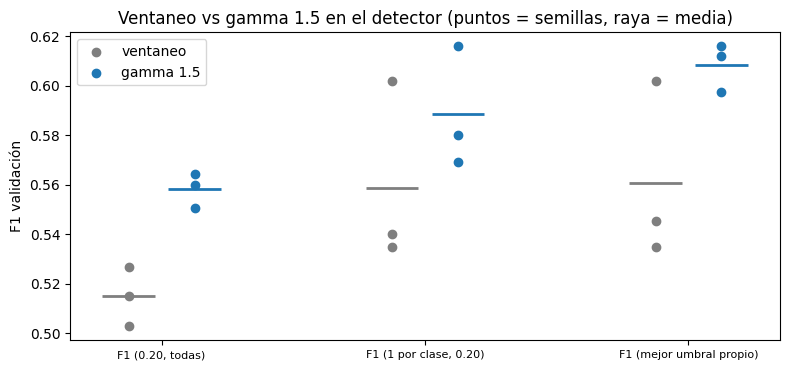

In [19]:
col_pp = f'F1 ({MODO}, {UMBRAL:.2f})'
filas = []
for prep, cache_p in CACHES.items():
    dd = np.load(cache_p); mv = np.asarray(dd['split_names'] == 'val')
    vx = torch.from_numpy(dd['images'][mv].astype(np.float32))
    vy = torch.from_numpy(dd['labels'][mv].astype(np.int64))
    for seed in SEMILLAS:
        m = detection_model_from_checkpoint(torch.load(ruta_prep(prep, seed), map_location='cpu',
                                                       weights_only=False)).eval()
        neutral = evaluar_deteccion(m, vx, vy, torch.device('cpu'), confidence=0.20)
        pp = evaluar_deteccion(m, vx, vy, torch.device('cpu'), confidence=UMBRAL, max_por_clase=MAX_POR_CLASE)
        propio = max((evaluar_deteccion(m, vx, vy, torch.device('cpu'), confidence=c, max_por_clase=1)
                      for c in UMBRALES), key=lambda r: r['f1'])
        filas.append({'preprocesamiento': prep, 'semilla': seed,
                      'F1 (0.20, todas)': neutral['f1'], col_pp: pp['f1'],
                      'F1 (mejor umbral propio)': propio['f1'],
                      'precisión': pp['precision'], 'recall': pp['recall'], 'FP': int(pp['falsos_positivos'])})
comp = pd.DataFrame(filas)
print('Por semilla:'); display(comp.round(3))
METRICAS = ['F1 (0.20, todas)', col_pp, 'F1 (mejor umbral propio)']
media = comp.groupby('preprocesamiento')[METRICAS + ['precisión', 'recall', 'FP']].mean()
desv = comp.groupby('preprocesamiento')[METRICAS].std()
print('Media por preprocesamiento:'); display(media.round(3))

print('Veredicto (gamma 1.5 − ventaneo):')
for met in METRICAS:
    dif = media.loc['gamma 1.5', met] - media.loc['ventaneo', met]
    pares = comp.pivot(index='semilla', columns='preprocesamiento', values=met)
    gana = int((pares['gamma 1.5'] > pares['ventaneo']).sum())
    if len(SEMILLAS) > 1:
        ruido = float(desv[met].max())
        concl = 'diferencia clara' if abs(dif) > 2 * ruido else 'no concluyente'
        print(f'  {met:28s}: {dif:+.3f} | desviación entre semillas {ruido:.3f} | '
              f'gamma gana en {gana} de {len(SEMILLAS)} semillas → {concl}')
    else:
        print(f'  {met:28s}: {dif:+.3f} → {veredicto(media.loc["gamma 1.5", met], media.loc["ventaneo", met]).split("→ ")[1]}'
              .replace('CBAM', 'gamma'))

fig, ax = plt.subplots(figsize=(8, 3.8))
for k, prep in enumerate(CACHES):
    for j, met in enumerate(METRICAS):
        y = comp.loc[comp['preprocesamiento'] == prep, met].values
        x = j + (k - 0.5) * 0.25
        ax.scatter(np.full(len(y), x), y, color=['tab:gray', 'tab:blue'][k], label=prep if j == 0 else None, zorder=3)
        ax.hlines(y.mean(), x - 0.1, x + 0.1, color=['tab:gray', 'tab:blue'][k], lw=2)
ax.set_xticks(range(len(METRICAS))); ax.set_xticklabels(METRICAS, fontsize=8)
ax.set_ylabel('F1 validación'); ax.set_title('Ventaneo vs gamma 1.5 en el detector (puntos = semillas, raya = media)')
ax.legend(); plt.tight_layout(); fig.savefig('outputs/figures/week9_ventaneo_vs_gamma.png', dpi=120)
plt.show(); plt.close(fig)

**Lectura (corrida del equipo, 3 semillas por preprocesamiento):**

| F1 en validación (media de 3 semillas) | Ventaneo | Gamma 1.5 | Diferencia | Gamma gana en |
|---|---|---|---|---|
| Umbral 0.20, todas las cajas (neutral) | 0.515 | **0.558** | **+0.043** | **3 de 3 semillas** |
| Post-proceso de 5.1 (1 por clase, 0.20) | 0.559 | 0.588 | +0.030 | 2 de 3 |
| Mejor umbral propio (el más justo) | 0.561 | **0.608** | +0.048 | 2 de 3 |

- **Gamma 1.5 da mejores predicciones que el ventaneo solo.** Gana en promedio en las tres formas de medir. Con el umbral neutral la diferencia es clara: gana en las tres semillas, y la diferencia (+0.043) es más de tres veces la variación entre semillas (0.012). Con el mejor umbral de cada modelo la ventaja es todavía mayor (+0.048), pero en una de las tres semillas (la 7) el ventaneo empata (0.602 contra 0.597), así que con el criterio estricto queda como no concluyente.
- **La ventaja viene de la precisión, no del recall.** Los dos encuentran la misma proporción de regiones (recall 0.524 en ambos), pero gamma comete menos falsos positivos: 42 contra 57 en promedio (precisión 0.680 contra 0.599). Es lo mismo que mostró Otsu en la sección 1.2 (precisión 0.67 contra 0.51): al oscurecer el tejido blando, gamma hace que el modelo lo confunda menos con hueso.
- **Las tres mediciones cuentan una historia coherente:** gamma no pierde información del hueso (mismo Dice óptimo), reduce el ruido del tejido blando (CNR 8.1 contra 6.6) y eso se traduce en un detector con menos cajas falsas.
- **Cuidado:** son 3 semillas y 15 casos de validación. Es evidencia consistente a favor de gamma, no una prueba estadística; para el informe final se puede repetir con el modelo de la semana 10.

## 6. Primeras bounding boxes en validación

Casos de validación, nunca vistos en entrenamiento. Caja **continua = verdad (GT)**, **discontinua = predicción** con su confianza; color por región (azul sacro, verde coxal izquierdo, rojo coxal derecho). Se muestra el corte central del caché de cada caso.

Primero el caso 014 con el script del entregable, que deja **una caja por región** (la de mayor confianza) para que la figura sea legible:

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/visualize_week9_validation.py --checkpoint outputs/week9_det_cbam32.pth --case-id 014 --confidence 0.2 --output outputs/figures/week9_detection_validation_014.png
Guardado: outputs/figures/week9_detection_validation_014.png


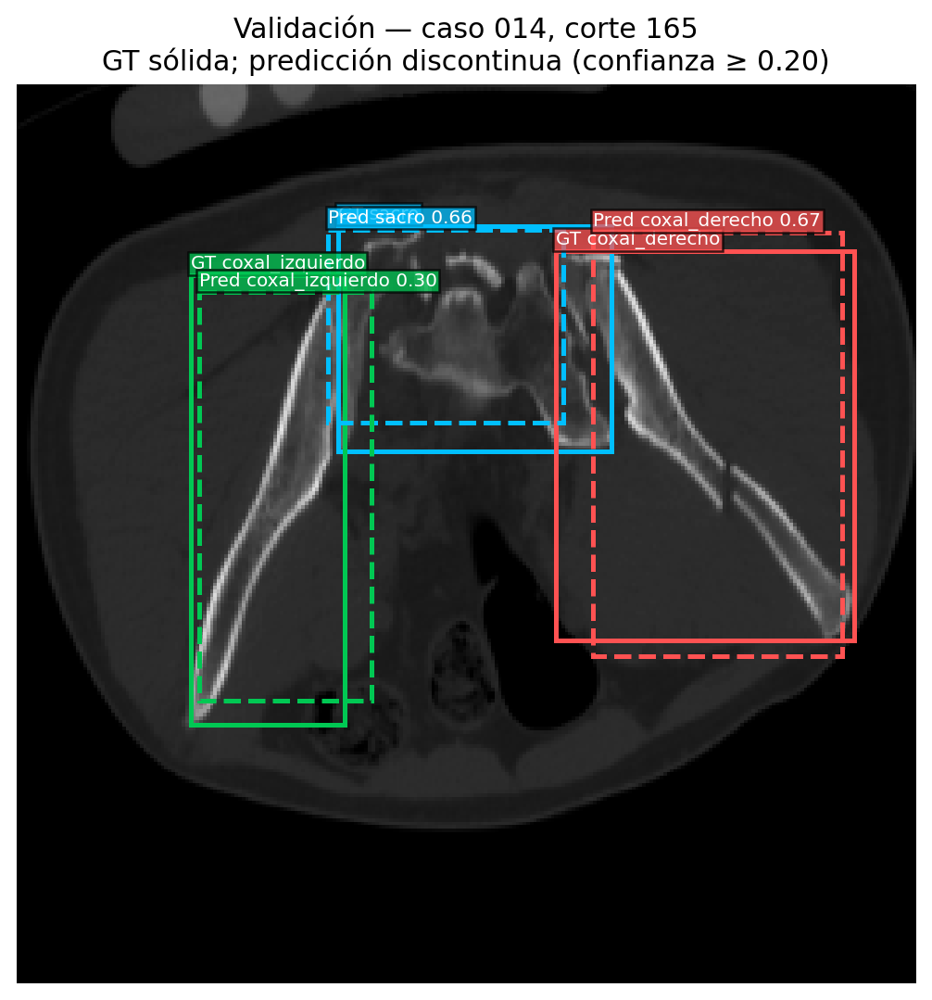

In [20]:
_ = run(f'python src/visualize_week9_validation.py --checkpoint {MODELOS["con CBAM"][0]} --case-id 014 '
        f'--confidence {UMBRAL} --output outputs/figures/week9_detection_validation_014.png')
# El script del entregable ya deja una caja por región (la de mayor confianza).
display(Image('outputs/figures/week9_detection_validation_014.png', width=650))

Luego los 15 casos de validación en un solo mosaico, con el post-proceso elegido en 5.1. Arriba de cada caso se indica cuántas cajas había antes de limitar a una por clase, para ver qué se descartó. Se dibuja con las mismas funciones del script (`draw`, `decode_predictions`) y el mismo corte; se guarda en `outputs/figures/week9_val_mosaico.png`.

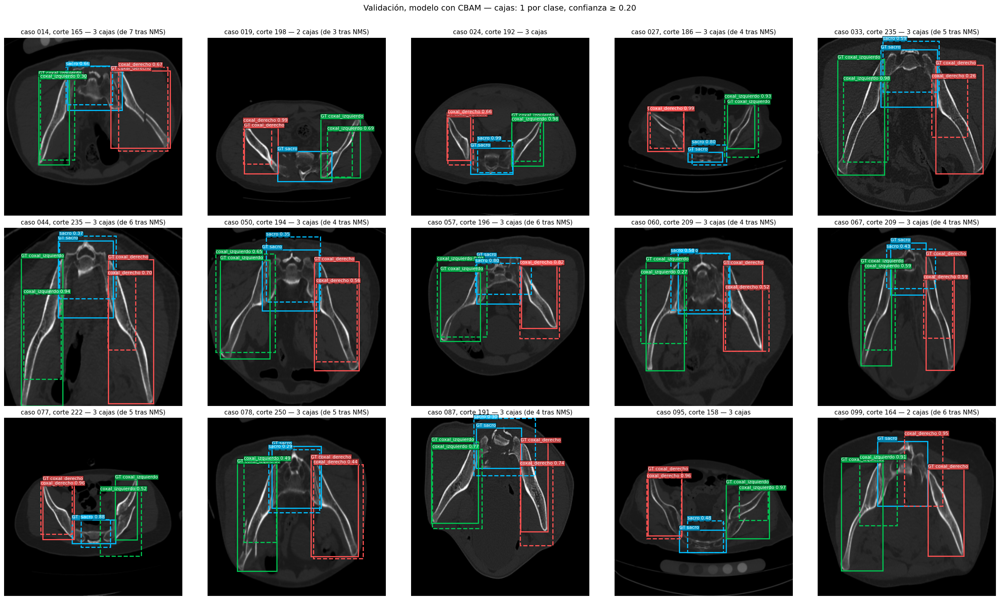

In [21]:
from week9_detection import boxes_from_label, decode_predictions
from visualize_week9_validation import draw, REGION_NAMES

model = detection_model_from_checkpoint(torch.load(MODELOS['con CBAM'][0], map_location='cpu', weights_only=False))
model.eval()

ids_cache = d['case_ids']; val_idx = np.flatnonzero(d['split_names'] == 'val')
val_casos = list(dict.fromkeys(ids_cache[val_idx]))           # orden del caché, sin repetir
fig, axes = plt.subplots(3, 5, figsize=(25, 15))
for ax, cid in zip(axes.ravel(), val_casos):
    cand = val_idx[ids_cache[val_idx] == cid]; i = int(cand[len(cand) // 2])   # mismo corte que el script
    img = torch.from_numpy(d['images'][i:i + 1].astype(np.float32))
    lab = torch.from_numpy(d['labels'][i:i + 1].astype(np.int64))
    with torch.no_grad():
        salida = model(img)
    todas = decode_predictions(salida, confidence=UMBRAL)[0]
    pred = decode_predictions(salida, confidence=UMBRAL, max_por_clase=MAX_POR_CLASE)[0]
    ax.imshow(img[0, 0], cmap='gray', vmin=0, vmax=1)
    for item in boxes_from_label(lab)[0]:
        draw(ax, item, f"GT {REGION_NAMES[int(item['class_id'])]}", 'solid')
    for item in pred:
        draw(ax, item, f"{REGION_NAMES[int(item['class_id'])]} {item['score']:.2f}", 'dashed')
    extra = f' (de {len(todas)} tras NMS)' if len(todas) != len(pred) else ''
    ax.set_title(f"caso {cid}, corte {int(d['z_indices'][i])} — {len(pred)} cajas{extra}", fontsize=11)
    ax.axis('off')
for ax in axes.ravel()[len(val_casos):]:
    ax.axis('off')
fig.suptitle(f'Validación, modelo con CBAM — cajas: {MODO}, confianza ≥ {UMBRAL:.2f}', fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.97)); fig.savefig('outputs/figures/week9_val_mosaico.png', dpi=80)
plt.show(); plt.close(fig)

### 6.1 ¿De qué tipo son los errores?

El mosaico muestra un corte por caso; esta tabla cuenta los errores en los **60 cortes** de validación con el umbral elegido, con todas las cajas y con una por clase. Cada predicción se empareja como en `match_detections` (uno a uno, por confianza, IoU ≥ 0.5, misma clase); las que sobran se clasifican así:

- **duplicada**: cae sobre una región que ya tenía su acierto (IoU ≥ 0.5 con esa caja real).
- **clase equivocada**: cae bien sobre una región, pero con la etiqueta de otra (por ejemplo, coxal izquierdo llamado derecho).
- **mal localizada**: clase correcta, pero solapa poco con la caja real (0.1 ≤ IoU < 0.5).
- **fondo**: no corresponde a ninguna región.

Y para cada región **no detectada** se mira qué tenía el modelo por debajo del umbral (confianza ≥ 0.05):

- **descartada al dejar una por clase**: había una caja correcta (IoU ≥ 0.5) por encima del umbral, pero otra caja de su clase tenía más puntaje y se quedó esa.
- **caja correcta con puntaje bajo**: había una caja de su clase con IoU ≥ 0.5, pero no llegó al umbral.
- **caja mal ubicada**: la caja de su clase solapa poco (IoU < 0.5): el modelo la vio pero no acertó el tamaño o la posición.
- **detectada con otra clase**: la región tiene encima una caja de otra clase.
- **el modelo no la ve**: no hay ninguna caja razonable sobre ella.

In [22]:
def iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def caja(item):
    return [float(v) for v in item['box']]


def clasificar_errores(max_pc):
    errores = {'acierto': 0, 'duplicada': 0, 'clase equivocada': 0, 'mal localizada': 0, 'fondo': 0,
               'región no detectada': 0}
    confusiones, perdidas = [], []          # perdidas: (indice de corte, caja real) no detectadas
    with torch.no_grad():
        for i in val_idx:
            img = torch.from_numpy(d['images'][i:i + 1].astype(np.float32))
            lab = torch.from_numpy(d['labels'][i:i + 1].astype(np.int64))
            pred = sorted(decode_predictions(model(img), confidence=UMBRAL, max_por_clase=max_pc)[0],
                          key=lambda p: -float(p['score']))
            gt = boxes_from_label(lab)[0]
            libres = set(range(len(gt)))
            for p in pred:
                pb, pc = caja(p), int(p['class_id'])
                misma = [(iou(pb, caja(gt[k])), k) for k in range(len(gt)) if int(gt[k]['class_id']) == pc]
                cand = [(v, k) for v, k in misma if k in libres]
                if cand and max(cand)[0] >= 0.5:
                    errores['acierto'] += 1; libres.discard(max(cand)[1]); continue
                otra = [(iou(pb, caja(gt[k])), int(gt[k]['class_id'])) for k in range(len(gt))
                        if int(gt[k]['class_id']) != pc]
                if misma and max(misma)[0] >= 0.5:
                    errores['duplicada'] += 1
                elif otra and max(otra)[0] >= 0.5:
                    errores['clase equivocada'] += 1
                    confusiones.append((str(ids_cache[i]), REGION_NAMES[max(otra)[1]], REGION_NAMES[pc]))
                elif misma and max(misma)[0] >= 0.1:
                    errores['mal localizada'] += 1
                else:
                    errores['fondo'] += 1
            errores['región no detectada'] += len(libres)
            perdidas += [(int(i), gt[k]) for k in libres]
    return errores, confusiones, perdidas


n_gt = sum(len(boxes_from_label(torch.from_numpy(d['labels'][i:i + 1].astype(np.int64)))[0]) for i in val_idx)
TIPOS_FP = ('duplicada', 'clase equivocada', 'mal localizada', 'fondo')
desglose = {modo: clasificar_errores(mpc) for modo, mpc in MODOS.items()}
print(f"Umbral {UMBRAL:.2f} | cajas reales {n_gt}\n")
print(f"{'':24s}" + ''.join(f'{m:>14s}' for m in MODOS))
for k in ('acierto', 'región no detectada') + TIPOS_FP:
    etiqueta = k if k in ('acierto', 'región no detectada') else f'FP {k}'
    print(f'{etiqueta:24s}' + ''.join(f'{desglose[m][0][k]:14d}' for m in MODOS))

errores, confusiones, perdidas = desglose[MODO]
n_fp = sum(errores[k] for k in TIPOS_FP)
if confusiones:
    print(f'\nConfusiones de clase con cajas = {MODO} (caso: real → predicha):')
    for cid, real, predicha in confusiones:
        print(f'  {cid}: {real} → {predicha}')

# ¿Por qué no se detectó cada región perdida? Se mira todo lo que el modelo propone con confianza ≥ 0.05.
motivo = {'descartada al dejar una por clase': 0, 'caja correcta con puntaje bajo': 0, 'caja mal ubicada': 0,
          'detectada con otra clase': 0, 'el modelo no la ve': 0}
por_clase = {n: 0 for n in REGION_NAMES}
with torch.no_grad():
    for i, g in perdidas:
        img = torch.from_numpy(d['images'][i:i + 1].astype(np.float32))
        bajas = decode_predictions(model(img), confidence=0.05)[0]
        gb, gc = caja(g), int(g['class_id'])
        misma = max([iou(caja(p), gb) for p in bajas if int(p['class_id']) == gc], default=0.0)
        otra = max([iou(caja(p), gb) for p in bajas if int(p['class_id']) != gc], default=0.0)
        sobre_umbral = max([iou(caja(p), gb) for p in bajas
                            if int(p['class_id']) == gc and float(p['score']) >= UMBRAL], default=0.0)
        if sobre_umbral >= 0.5:
            motivo['descartada al dejar una por clase'] += 1
        elif misma >= 0.5:
            motivo['caja correcta con puntaje bajo'] += 1
        elif misma >= 0.1:
            motivo['caja mal ubicada'] += 1
        elif otra >= 0.5:
            motivo['detectada con otra clase'] += 1
        else:
            motivo['el modelo no la ve'] += 1
        por_clase[REGION_NAMES[gc]] += 1
print(f'\nRegiones no detectadas con cajas = {MODO}: {len(perdidas)} de {n_gt}')
for k, v in motivo.items():
    print(f'  {k:32s}: {v:3d}')
print('  por región:', por_clase)

Umbral 0.20 | cajas reales 164

                                 todas   1 por clase
acierto                            110            97
región no detectada                 54            67
FP duplicada                         8             0
FP clase equivocada                  9             3
FP mal localizada                   61            32
FP fondo                            41            19

Confusiones de clase con cajas = 1 por clase (caso: real → predicha):
  019: coxal_derecho → sacro
  067: coxal_izquierdo → coxal_derecho
  095: coxal_izquierdo → coxal_derecho

Regiones no detectadas con cajas = 1 por clase: 67 de 164
  descartada al dejar una por clase:  13
  caja correcta con puntaje bajo  :   9
  caja mal ubicada                :  31
  detectada con otra clase        :   1
  el modelo no la ve              :  13
  por región: {'sacro': 29, 'coxal_izquierdo': 16, 'coxal_derecho': 22}


**Lectura (qué se ve en las cajas):**

- **Lo que funciona:** en la gran mayoría de los cortes las cajas caen sobre la anatomía correcta, con el sacro al centro y cada coxal en su lado. Es lo que pide el entregable: predicciones visualmente razonables en pacientes no vistos.
- **Cajas repetidas de la misma clase.** El coxal es largo y curvo; el modelo a veces propone una caja para la mitad superior y otra para la inferior, con puntajes muy distintos. Como se solapan menos de IoU 0.5, el NMS no elimina ninguna (el NMS solo mira el solapamiento, no la diferencia de puntaje). Limitar a una caja por clase las elimina; la tabla de 6.1 muestra cuántas había con todas las cajas y cuántas quedan.
- **Confusión izquierda/derecha.** Si la tabla de 6.1 lista confusiones, casi siempre son de este tipo: un coxal etiquetado como el del lado contrario. El modelo decide el lado por la posición en la imagen, y en cortes donde la pelvis está girada o un coxal se ve incompleto esa pista falla. El flip sagital con intercambio de etiquetas de la semana 10 apunta justamente a esto.
- **Regiones sin caja.** Son el error que más pesa (el recall ronda 0.6) y el diagnóstico de 6.1 separa sus causas. En la corrida del equipo casi todas las perdidas tenían alguna caja de su clase cerca: mal ubicada, con puntaje bajo o descartada al dejar una por clase. Las regiones que el modelo de verdad no ve son pocas. O sea, el detector **encuentra** las regiones pero no ajusta bien la caja ni ordena bien sus propias propuestas: es falta de entrenamiento con solo 96 cortes, no un error del post-proceso. El sacro es la región que más se pierde. Hay además una razón de diseño: cada región se asigna a **una sola celda** del grid (la de su centro), y en el coxal, largo y curvo, el centro de la caja suele caer en tejido blando, lejos del hueso. El modelo tiene que aprender a "disparar" en una celda donde no hay hueso, con un solo ejemplo positivo por región y por corte.
- **Qué lo mejoraría (semana 10 en adelante):** más cortes de entrenamiento y aumento de datos, y asignar cada región a varias celdas cercanas a su centro en vez de a una.
- **Implicación para la semana 10:** el detector sirve para localizar las regiones, pero no basta para separar fragmentos. Por eso la semana 10 agrega la segmentación de instancias sobre estas regiones.

### 6.2 Fragmentos desplazados (pedido del avance)

El profesor quiere ver qué hace el detector con **fragmentos separados de su hueso**. Acepta que los encierre en la caja del hueso o que les ponga una caja aparte, **siempre que sea de la misma clase**; no acepta que los ignore ni que les ponga la clase de otro hueso.

Para cada caso de validación se miden en 3D, sobre la etiqueta real, las distancias borde a borde de cada fragmento secundario a su principal (`fragment_distances.py`, en mm con el spacing del header). Se toman los dos más alejados de cada caso (a más de 2 mm), el corte donde más se ven, y se da un veredicto según la caja que más cubre el fragmento (al menos la mitad):

- **misma clase**: lo que el profesor acepta.
- **otra clase**: lo cubre una caja de otro hueso.
- **ninguna**: ninguna caja lo cubre (ignorado).

Se evalúa con todas las cajas y con una caja por clase, porque limitar a una por clase puede dejar fuera un fragmento lejano que tenía su propia caja. También se anota si el corte está dentro del rango axial con que se entrenó el detector (15 %–85 % de la extensión ósea).

$ "c:\Users\Administrador\Documents\02_PROYECTO_PENGWIN\proyecto2-analitica-datos\.venv\Scripts\python.exe" src/deteccion_fragmentos_desplazados.py --checkpoint outputs/week9_det_cbam32.pth --split val --top 2 --min-dist 2 --confidence 0.2
caso 014 z=211 frag 24 coxal_derecho 4.1 mm (posición 0.83) → ninguna / ninguna
caso 024 z=50 frag 13 coxal_izquierdo 19.1 mm (posición 0.11) → ninguna / ninguna
caso 024 z=31 frag 14 coxal_izquierdo 3.4 mm (posición 0.04) → otra clase / otra clase
caso 087 z=33 frag 14 coxal_izquierdo 5.4 mm (posición 0.02) → ninguna / ninguna
caso 099 z=86 frag 12 coxal_izquierdo 12.9 mm (posición 0.24) → otra clase / otra clase

5 fragmentos a ≥ 2.0 mm de su principal (val)
  todas las cajas : {'ninguna': 3, 'otra clase': 2}
  1 por clase     : {'ninguna': 3, 'otra clase': 2}
  dentro del rango axial de entrenamiento: {False: 3, True: 2}
Guardado en outputs\figures\week9_desplazados


,caso,z,region,fragmento,dist_mm,pixeles_256,posicion_axial,dentro_rango_entrenamiento,veredicto_todas,cobertura_todas,caja_todas,veredicto_1_por_clase,cobertura_1_por_clase
0,024,50,coxal_izquierdo,13,19.1,44,0.11,False,ninguna,0.00,NaN,ninguna,0.00
1,099,86,coxal_izquierdo,12,12.9,651,0.24,True,otra clase,0.59,sacro,otra clase,0.59
2,087,33,coxal_izquierdo,14,5.4,187,0.02,False,ninguna,0.00,NaN,ninguna,0.00
3,014,211,coxal_derecho,24,4.1,249,0.83,True,ninguna,0.00,NaN,ninguna,0.00
4,024,31,coxal_izquierdo,14,3.4,57,0.04,False,otra clase,1.00,sacro,otra clase,1.00


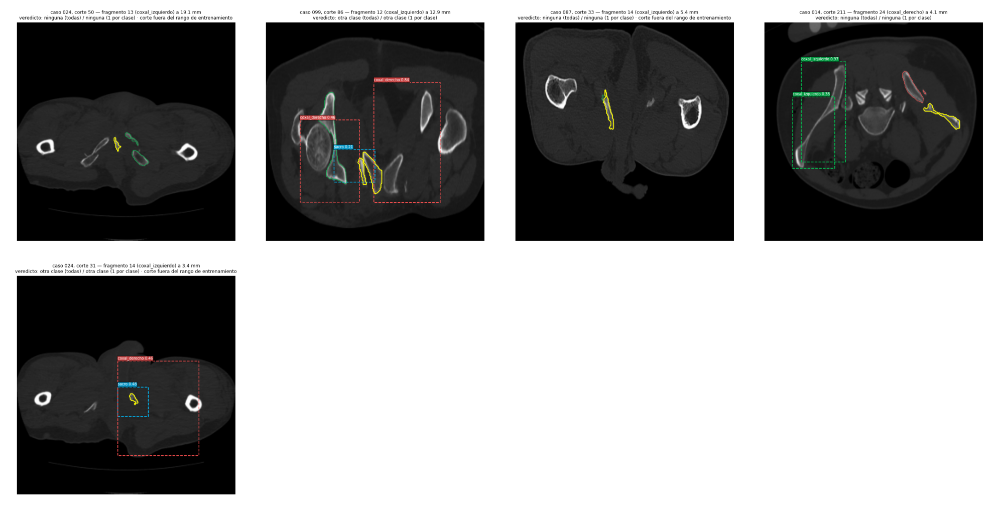

In [23]:
salida_desp = run(f'python src/deteccion_fragmentos_desplazados.py --checkpoint {MODELOS["con CBAM"][0]} '
                  f'--split val --top 2 --min-dist 2 --confidence {UMBRAL}')
desp = pd.read_csv('outputs/figures/week9_desplazados/resumen.csv', dtype={'caso': str})
if len(desp):
    desp = desp.sort_values('dist_mm', ascending=False).reset_index(drop=True)
    display(desp)
    rutas = [f"outputs/figures/week9_desplazados/desplazado_{r.caso}_{r.fragmento}.png" for r in desp.itertuples()]
    fig, axes = plt.subplots(int(np.ceil(len(rutas) / 4)), 4, figsize=(20, 5.2 * int(np.ceil(len(rutas) / 4))), squeeze=False)
    for ax, ruta in zip(axes.ravel(), rutas):
        ax.imshow(plt.imread(ruta)); ax.axis('off')
    for ax in axes.ravel()[len(rutas):]:
        ax.axis('off')
    plt.tight_layout(); fig.savefig('outputs/figures/week9_desplazados_mosaico.png', dpi=80)
    plt.show(); plt.close(fig)

**Lectura (corrida del equipo):** ninguno de los 5 fragmentos desplazados de validación queda en una caja de su propio hueso: 3 quedan sin caja y 2 bajo una caja de otra clase. El detector de la semana 9 **todavía no cumple** lo que pidió el profesor para fragmentos desplazados. Las causas se ven en las figuras:

- **Tres están en cortes que el detector nunca vio** (posición axial 0.02–0.11: pubis e isquion, a la altura de las cabezas femorales). Es el caso del **087** que mencionó el profesor: en ese corte el detector no propone ninguna caja. Los dos fragmentos del 024 están en el mismo nivel; uno queda sin caja y el otro bajo una caja de sacro.
- **Dos están dentro del rango de entrenamiento y aun así fallan.** En el 099 (corte bajo, posición 0.24) el fragmento de coxal izquierdo, a 12.9 mm de su hueso, queda bajo una caja de sacro, y el lado izquierdo aparece etiquetado como coxal derecho: es la confusión izquierda/derecha de la sección 6.1. En el 014 (corte alto, 0.83) el coxal derecho completo, con su fragmento a 4.1 mm, no tiene ninguna caja.
- **Qué hacer:** entrenar con la extensión completa del hueso (`--extent 0 1`) para que el modelo vea los cortes de los extremos, con más casos (la semana 10 ya usa 70) y con el flip sagital con intercambio de etiquetas, que ataca la confusión de lados. Para la demo corte a corte es necesario, porque los fragmentos desplazados suelen estar justo en esos extremos.

In [24]:
# Opcional: una figura por caso (100 PNG) para revisarlas una a una fuera del notebook.
# No se muestran aquí para no inflar el notebook (~11 MB); quedan en outputs/figures/preproc_casos/.
GUARDAR_100_INDIVIDUALES = False

if GUARDAR_100_INDIVIDUALES:
    out_dir = Path('outputs/figures/preproc_casos'); out_dir.mkdir(parents=True, exist_ok=True)
    for cid in casos:
        c = load_case(cid); z = corte_con_mas_hueso(c)
        img = resize_slice(window_hu(c.image[z]), 256); lab = resize_label_slice(c.label[z], 256)
        fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
        ax[0].imshow(img, cmap='gray', vmin=0, vmax=1); ax[0].set_title(f'caso {cid}  z={z}  (entrada al modelo)')
        ax[1].imshow(img, cmap='gray', vmin=0, vmax=1); ax[1].contour(lab > 0, levels=[0.5], colors='r', linewidths=0.6)
        ax[1].set_title(f'brillo hueso = {brillo[cid]:.2f}')
        for a in ax: a.axis('off')
        plt.tight_layout(); fig.savefig(out_dir / f'{cid}.png', dpi=100); plt.close(fig)
    print(f'100 figuras guardadas en {out_dir}')
else:
    print('Omitido (GUARDAR_100_INDIVIDUALES = False)')

Omitido (GUARDAR_100_INDIVIDUALES = False)


## 7. Resumen de la semana 9

La tabla se arma con los números de **esta ejecución** (no se copia a mano), para pegarla en `docs/resumen_semana9.md` o en el informe.

In [25]:
import pandas as pd

cnr = pd.read_csv('data/experimento_normalizacion_resumen.csv')
ngc = cnr[cnr['nombre'].str.startswith('NGC')]
filas = pd.concat([cnr[~cnr['nombre'].str.startswith('NGC')], ngc.nlargest(1, 'cnr'), ngc.nsmallest(1, 'cnr')])
print(f'Experimento de normalización ({len(cnr)} configuraciones, promedio de 5 casos): '
      'referencias, escalera de gamma y la mejor y peor NGC-CLAHE')
display(filas[['nombre', 'sd_blando', 'contraste', 'cnr']].sort_values('cnr', ascending=False).round(3))

con, sin = mejores['con CBAM'], mejores['sin CBAM']
bc, bs = barrido[('con CBAM', MODO, UMBRAL)], barrido[('sin CBAM', MODO, UMBRAL)]
b3g = barrido[('CBAM 3 etapas + γ', MODO, UMBRAL)]
og = otsu['gamma 1.5 (elegido)']; ov = otsu['ventaneo']; oc = otsu['CLAHE']
dv = desp['veredicto_todas'].value_counts().to_dict() if len(desp) else {}
en = energia.groupby('modelo')['energia_en_caja'].mean().to_dict() if energia is not None else {}
mp = media['F1 (mejor umbral propio)']
tabla = f'''
| Requisito | Evidencia | Resultado |
|---|---|---|
| Preprocesamiento de entrada | `pengwin_io.window_hu`, `comparar_gamma.py`, sección 1 | ventana ósea + gamma 1.5; brillo del hueso {vals.mean():.3f} ± {vals.std():.3f} en 100 casos, {len(atipicos)} atípicos |
| Backbone + CBAM + cabeza de detección | `week9_detection.py`, sección 2 | grid 16×16, NMS propio por clase, {parametros[True]:,} parámetros (CBAM: {parametros[True] - parametros[False]:,}) |
| Overfit sobre batch pequeño | `train_overfit_detection.py`, sección 3 | pérdida {overfit['inicial']:.5f} → {overfit['final']:.5f} ({overfit['reduccion']:.0f}×; criterio ≥ 4×) |
| Entrenamiento multi-paciente | `train_week9_detection.py`, sección 4 | 96 cortes train / 60 val; mejor época {con['epoch']} (con CBAM) y {sin['epoch']} (sin CBAM), elegidas por F1 |
| Ablación de CBAM (conf. 0.20) | sección 5 | F1 {con['f1']:.3f} con CBAM vs {sin['f1']:.3f} sin CBAM — {veredicto(con['f1'], sin['f1']).split('→ ')[1]} |
| Post-proceso calibrado (cajas: {MODO}, conf. {UMBRAL:.2f}) | sección 5.1 | F1 {bc['f1']:.3f} (P {bc['precision']:.3f}, R {bc['recall']:.3f}, FP {int(bc['falsos_positivos'])}) con CBAM vs {bs['f1']:.3f} sin CBAM ({veredicto(bc['f1'], bs['f1']).split('→ ')[1]}) — optimista, elegido sobre validación |
| Otsu vs label (pedido del avance) | `otsu_preprocesamiento.py`, sección 1.2 | Dice Otsu: ventaneo {ov['dice']:.2f}, gamma 1.5 {og['dice']:.2f}, CLAHE {oc['dice']:.2f}; Dice óptimo: {ov['dice_optimo']:.2f} / {og['dice_optimo']:.2f} / {oc['dice_optimo']:.2f} |
| Aporte de la atención por capa (γ) | sección 4.1 | γ por etapa: {', '.join(f'/{k} {v:+.2f}' for k, v in gammas.items())}; F1 {b3g['f1']:.3f} con 3 etapas |
| Grad-CAM con y sin atención | `gradcam_week9.py`, sección 5.2 | energía dentro de la caja real: {', '.join(f'{k} {100 * v:.0f} %' for k, v in en.items())} |
| Ventaneo vs gamma 1.5 en el detector | sección 5.3 | F1 con mejor umbral propio, media de {len(SEMILLAS)} semilla(s): ventaneo {mp['ventaneo']:.3f}, gamma 1.5 {mp['gamma 1.5']:.3f} |
| Fragmentos desplazados | `deteccion_fragmentos_desplazados.py`, sección 6.2 | {len(desp)} fragmentos a ≥ 2 mm: {', '.join(f'{k} {v}' for k, v in dv.items())} |
| Primeras bboxes razonables | `visualize_week9_validation.py`, sección 6 | {errores['acierto']} de {n_gt} regiones detectadas en 60 cortes ({len(perdidas)} sin detectar); FP: {errores['duplicada']} duplicadas, {errores['mal localizada']} mal localizadas, {errores['clase equivocada']} de clase equivocada, {errores['fondo']} en fondo |
'''
display(Markdown(tabla))

Experimento de normalización (166 configuraciones, promedio de 5 casos): referencias, escalera de gamma y la mejor y peor NGC-CLAHE


,nombre,sd_blando,contraste,cnr
0,solo gamma g=2.2,0.012,0.113,10.451
1,NGC g=2.2 clip=0.002 tejas=16 bins=256,0.012,0.113,10.342
19,solo gamma g=1.8,0.016,0.130,9.061
46,solo gamma g=1.5,0.020,0.142,8.107
85,solo gamma g=1.2,0.023,0.151,7.207
105,ventaneo (referencia),0.026,0.154,6.622
164,NGC g=1.0 clip=0.015 tejas=16 bins=256,0.073,0.207,3.234
165,CLAHE actual,0.089,0.244,3.231



| Requisito | Evidencia | Resultado |
|---|---|---|
| Preprocesamiento de entrada | `pengwin_io.window_hu`, `comparar_gamma.py`, sección 1 | ventana ósea + gamma 1.5; brillo del hueso 0.296 ± 0.042 en 100 casos, 6 atípicos |
| Backbone + CBAM + cabeza de detección | `week9_detection.py`, sección 2 | grid 16×16, NMS propio por clase, 1,773,322 parámetros (CBAM: 8,290) |
| Overfit sobre batch pequeño | `train_overfit_detection.py`, sección 3 | pérdida 1.67265 → 0.00115 (1454×; criterio ≥ 4×) |
| Entrenamiento multi-paciente | `train_week9_detection.py`, sección 4 | 96 cortes train / 60 val; mejor época 34 (con CBAM) y 32 (sin CBAM), elegidas por F1 |
| Ablación de CBAM (conf. 0.20) | sección 5 | F1 0.560 con CBAM vs 0.508 sin CBAM — no concluyente |
| Post-proceso calibrado (cajas: 1 por clase, conf. 0.20) | sección 5.1 | F1 0.616 (P 0.642, R 0.591, FP 54) con CBAM vs 0.589 sin CBAM (no concluyente) — optimista, elegido sobre validación |
| Otsu vs label (pedido del avance) | `otsu_preprocesamiento.py`, sección 1.2 | Dice Otsu: ventaneo 0.48, gamma 1.5 0.49, CLAHE 0.22; Dice óptimo: 0.67 / 0.67 / 0.60 |
| Aporte de la atención por capa (γ) | sección 4.1 | γ por etapa: /4 +0.09, /8 -0.11, /16 +0.11; F1 0.622 con 3 etapas |
| Grad-CAM con y sin atención | `gradcam_week9.py`, sección 5.2 | energía dentro de la caja real: CBAM 3 etapas + γ 55 %, con CBAM 39 %, sin CBAM 46 % |
| Ventaneo vs gamma 1.5 en el detector | sección 5.3 | F1 con mejor umbral propio, media de 3 semilla(s): ventaneo 0.561, gamma 1.5 0.608 |
| Fragmentos desplazados | `deteccion_fragmentos_desplazados.py`, sección 6.2 | 5 fragmentos a ≥ 2 mm: ninguna 3, otra clase 2 |
| Primeras bboxes razonables | `visualize_week9_validation.py`, sección 6 | 97 de 164 regiones detectadas en 60 cortes (67 sin detectar); FP: 0 duplicadas, 32 mal localizadas, 3 de clase equivocada, 19 en fondo |


**Decisiones de la semana 9:**

1. **Gamma 1.5 en lugar de CLAHE** como preprocesamiento de entrada, a partir de la asesoría y del barrido con evidencia (CNR 8.1 contra 3.2 de CLAHE y 6.6 del ventaneo solo). Global, sin ajustes por caso. En la tabla de arriba, la mejor NGC-CLAHE (CNR 10.3) queda casi igual a gamma 2.2 sola (10.45) porque con un clip tan bajo CLAHE prácticamente no actúa: **a igual gamma, agregar CLAHE nunca mejoró**. Gamma 2.2 no se eligió porque apaga el hueso de los casos oscuros.
2. **Selección del checkpoint por F1** a IoU ≥ 0.5 en lugar de IoU medio, que no castigaba las cajas sobrantes.
3. **32 canales base**: con 8 el modelo no tenía capacidad suficiente (F1 0.31); con 32 sube a ~0.5 en las mismas condiciones.
4. **CBAM se mantiene** (requisito del enunciado). La ablación está en la sección 5 con su veredicto; con una sola semilla se lee como indicio, no como prueba.
5. **Post-proceso:** una caja por región y por corte (el NMS no elimina cajas de la misma clase que se solapan poco) y umbral de confianza calibrado en validación. La cifra final se mide en test.
6. **Reubicación de regiones que chocan en la misma celda** del grid (antes se perdían del target).

**Pedidos del avance (2 de octubre), dónde están:**

7. **Otsu contra el label** (1.2): gamma 1.5 conserva toda la información del hueso (Dice óptimo 0.670, igual que el ventaneo), CLAHE la pierde (0.595) y con Otsu gamma queda primero (0.486). Se mantiene gamma 1.5.
8. **γ aprendible por etapa** (4.1): γ ≈ 0.1 en las tres etapas, aporte bajo según el criterio del profesor; la etapa /16 sigue creciendo al final.
9. **Grad-CAM con y sin atención** (5.2): con CBAM en tres etapas el modelo concentra el 55 % de la energía en la región correcta, contra 46 % sin atención y 40 % con CBAM en una sola etapa. Indicio a favor de la atención en varias escalas.
10. **Fragmentos desplazados** (6.2): 0 de 5 en una caja de su hueso. Tres están en cortes fuera del rango de entrenamiento (incluido el 087) y dos fallan por confusión de lados o por no detectar el coxal. Hay que entrenar con la extensión completa.
11. **Ventaneo vs gamma 1.5 en el detector** (5.3): con 3 semillas, gamma da mejor F1 en las tres formas de medir (+0.043 con umbral neutral, en las 3 semillas; +0.048 con el mejor umbral de cada uno). La ventaja viene de menos falsos positivos con el mismo recall.
12. **Demo final corte a corte:** aunque el modelo use 2.5D, la demostración debe correr corte por corte, a tamaño completo, detectando y segmentando en cada corte (~2 s por corte). Queda como requisito para la semana 11.

**Qué pasó después (semana 10):** los cachés y modelos de la semana 10 ya se regeneraron y reentrenaron con gamma 1.5 (`outputs/gamma/`, modelos `w10g_*`), así que entrenamiento e inferencia usan la misma función de preprocesamiento en todo el proyecto.

## 8. Conclusiones

- **La implementación es correcta.** Pasan las 19 pruebas unitarias (codificación del grid y NMS
  incluidas), y el overfit intencional baja la pérdida de 1.673 a 0.001 (1454×, con un criterio
  mínimo de 4×).
- **CBAM es barato.** Agrega 8 290 parámetros, el 0.47 % del modelo.
- **El aporte de CBAM a la detección no es concluyente.** El F1 en validación fue 0.560 con CBAM,
  0.508 sin CBAM y 0.542 con CBAM en tres etapas y γ. Las diferencias (+0.052 y +0.034) son menores
  que dos veces el salto típico entre épocas (0.076), así que no se afirma una mejora. Los γ por
  etapa quedaron en 0.108 o menos en valor absoluto (aporte parcial).
- **Gamma 1.5 se justifica frente a CLAHE.** Con Otsu contra las máscaras, gamma 1.5 iguala al
  ventaneo (Dice 0.486 contra 0.480; con umbral óptimo, 0.670 ambos), mientras que CLAHE cae a
  0.223. Por eso se descartó CLAHE.
- **Los errores están localizados.** De 164 cajas reales, el error más común es la caja mal ubicada
  (31), seguido de las que el modelo no ve (13). El sacro concentra la mayor parte (29).
- **Esta es la línea base.** El caché de esta semana tiene solo 96 cortes de train y 60 de val. El
  modelo multitarea de las semanas 10 y 11 (H6) llega a un mAP50 de 0.958 en test.